# WFD Spatial Workflow

This notebook implements the approved 23-step workflow using either an OGC GeoPackage or an Esri file geodatabase. It preserves source inputs, removes null/empty geometry and unnecessary Z/M from working copies, uses EPSG:3035 for analysis, and writes 16 validated outputs plus a run report.

The selected input must contain `Network_data(WSO1_ID, nextdownWSO1_ID, Source_ID, dist_mouth)`; all required datasets and known input conditions are validated at runtime.


In [1]:
# Dependency and capability preflight. This cell never installs packages.
import gc
import hashlib
import importlib
import platform
import subprocess
import sys
import traceback

required_modules = {
    "pandas": "pandas",
    "geopandas": "geopandas",
    "matplotlib": "matplotlib",
    "pyogrio": "pyogrio",
    "pyarrow": "pyarrow",
    "shapely": "shapely",
}
missing = []
dependency_versions = {"python": sys.version.split()[0], "executable": sys.executable}
for label, module_name in required_modules.items():
    try:
        module = importlib.import_module(module_name)
        dependency_versions[label] = getattr(module, "__version__", "unknown")
    except Exception as exc:
        missing.append(f"{label}: {type(exc).__name__}: {exc}")

try:
    import tkinter
    dependency_versions["tkinter"] = f"Tk {tkinter.TkVersion}"
except Exception as exc:
    missing.append(f"tkinter: {type(exc).__name__}: {exc}")

if missing:
    raise RuntimeError(
        "Required notebook dependencies are unavailable in "
        f"{sys.executable}:\n- " + "\n- ".join(missing)
    )

import os
import json
import shutil
import stat
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow
import pyogrio
import shapely
import tkinter as tk
from shapely import force_2d, make_valid
from shapely.geometry import GeometryCollection, MultiLineString, MultiPolygon, Point, Polygon
from tkinter import filedialog, messagebox, simpledialog

for capability in (force_2d, make_valid):
    if not callable(capability):
        raise RuntimeError(f"Required Shapely capability is unavailable: {capability}")

dependency_versions["gdal"] = getattr(pyogrio, "__gdal_version__", "unknown")
dependency_versions["geos"] = getattr(shapely, "geos_version_string", "unknown")
dependency_versions["platform"] = platform.platform()
pd.Series(dependency_versions, name="version")


python                              3.12.6
executable          /usr/local/bin/python3
pandas                               2.3.3
geopandas                            1.0.1
matplotlib                          3.10.7
pyogrio                             0.11.0
pyarrow                             22.0.0
shapely                              2.1.1
tkinter                             Tk 8.6
gdal                            (3, 10, 3)
geos                                3.13.1
platform      macOS-15.6.1-arm64-arm-64bit
Name: version, dtype: object

## Run Configuration

For interactive execution, leave input and profile values as `None` and use the dialogs. For unattended execution, set every required value explicitly. The test batch override is optional, disabled by default, and prohibited for full runs.


In [2]:
def env_bool(name, default=False):
    value = os.environ.get(name)
    if value is None:
        return default
    return value.strip().lower() in {"1", "true", "yes", "on"}


execution_mode = os.environ.get("WFD_EXECUTION_MODE", "interactive").lower()
configured_input_format = os.environ.get("WFD_INPUT_FORMAT")
configured_input_path = os.environ.get("WFD_INPUT_PATH")
configured_run_profile = os.environ.get("WFD_RUN_PROFILE")
configured_arcgis_python = os.environ.get("WFD_ARCGIS_PYTHON")
test_batch_size_override = (
    int(os.environ["WFD_TEST_BATCH_SIZE"])
    if os.environ.get("WFD_TEST_BATCH_SIZE") else None
)
compare_with_existing_output = env_bool("WFD_COMPARE_WITH_EXISTING_OUTPUT", False)

initial_batch_size = 1_000
minimum_batch_size = 25
maximum_batch_size = 5_000
high_candidate_count = 100_000
low_candidate_count = 10_000
map_sample_limit = 20_000
retain_cache_after_success = env_bool("WFD_RETAIN_CACHE", False)
minimum_free_space_gb = float(os.environ.get("WFD_MIN_FREE_SPACE_GB", "10"))
disk_space_input_multiplier = float(os.environ.get("WFD_DISK_INPUT_MULTIPLIER", "2.5"))

if execution_mode not in {"interactive", "unattended"}:
    raise ValueError("execution_mode must be 'interactive' or 'unattended'")
if minimum_free_space_gb <= 0 or disk_space_input_multiplier <= 0:
    raise ValueError("Disk-space safeguards must be positive")


In [3]:
def resolve_workflow_dir(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        direct = candidate / "Workflow_WFD"
        if (direct / "Data").is_dir() and (direct / "Workflow_diagram").is_dir():
            return direct
        if candidate.name == "Workflow_WFD" and (candidate / "Data").is_dir():
            return candidate
    raise RuntimeError("Could not resolve the Workflow_WFD project directory")

workflow_dir = resolve_workflow_dir()
output_dir = workflow_dir / "Output"
notebook_path = output_dir / "output_notebook.ipynb"
output_dir.mkdir(parents=True, exist_ok=True)
workflow_dir


PosixPath('/Users/eleshuk/Documents/ISA_class_materials/Thesis/Spatial_workflow_work/Workflow_WFD')

In [4]:
def choose_interactive_input():
    root = tk.Tk()
    root.withdraw()
    try:
        use_gpkg = messagebox.askyesno(
            "Input format",
            "Select Yes for GeoPackage or No for Esri file geodatabase.",
            parent=root,
        )
        if use_gpkg:
            value = filedialog.askopenfilename(
                title="Select input GeoPackage",
                filetypes=[("GeoPackage", "*.gpkg")],
                parent=root,
            )
            return "gpkg", Path(value) if value else None
        value = filedialog.askdirectory(
            title="Select input .gdb directory", parent=root
        )
        return "gdb", Path(value) if value else None
    finally:
        root.destroy()


def confirm_profile_interactively(suggested):
    root = tk.Tk()
    root.withdraw()
    try:
        use_suggestion = messagebox.askyesno(
            "Run profile",
            f"The selected path suggests the '{suggested}' profile. Use it?",
            parent=root,
        )
        if use_suggestion:
            return suggested
        alternative = "full" if suggested == "test" else "test"
        confirm = messagebox.askyesno(
            "Confirm alternative",
            f"Use the '{alternative}' profile instead?",
            parent=root,
        )
        if not confirm:
            raise RuntimeError("Run profile was not confirmed")
        return alternative
    finally:
        root.destroy()


if execution_mode == "interactive":
    input_format, input_path = choose_interactive_input()
    if input_path is None:
        raise RuntimeError("Input selection was cancelled")
else:
    if configured_input_format is None or configured_input_path is None:
        raise RuntimeError("Unattended execution requires configured input format and path")
    input_format = configured_input_format.lower()
    input_path = Path(configured_input_path)

input_path = input_path.expanduser().resolve()
if input_format == "gpkg":
    if not input_path.is_file() or input_path.suffix.lower() != ".gpkg":
        raise ValueError("GeoPackage mode requires an existing .gpkg file")
elif input_format == "gdb":
    if not input_path.is_dir() or input_path.suffix.lower() != ".gdb":
        raise ValueError("Geodatabase mode requires an existing .gdb directory")
else:
    raise ValueError("Input format must be 'gpkg' or 'gdb'")

test_root = (workflow_dir / "Data" / "test_data").resolve()
try:
    input_path.relative_to(test_root)
    suggested_run_profile = "test"
    profile_suggestion_basis = "selected path is under Workflow_WFD/Data/test_data"
except ValueError:
    suggested_run_profile = "full"
    profile_suggestion_basis = "selected path is outside Workflow_WFD/Data/test_data"

if execution_mode == "interactive":
    run_profile = confirm_profile_interactively(suggested_run_profile)
else:
    if configured_run_profile not in {"full", "test"}:
        raise RuntimeError("Unattended execution requires run_profile 'full' or 'test'")
    run_profile = configured_run_profile

profile_warning = None
if run_profile != suggested_run_profile:
    profile_warning = (
        f"Confirmed profile '{run_profile}' differs from suggested "
        f"'{suggested_run_profile}': {profile_suggestion_basis}"
    )
    warnings.warn(profile_warning)

if test_batch_size_override is not None:
    if run_profile != "test":
        raise ValueError("test_batch_size_override is prohibited for full runs")
    if not isinstance(test_batch_size_override, int) or test_batch_size_override <= 0:
        raise ValueError("test_batch_size_override must be a positive integer")
if compare_with_existing_output and run_profile != "test":
    raise ValueError("Cross-format output comparison is available only for test runs")

run_output_dir = output_dir if run_profile == "full" else output_dir / "test_runs"
final_output_gpkg = run_output_dir / "Workflow_outputs.gpkg"
previous_successful_output_present = final_output_gpkg.exists()
validation_report_path = run_output_dir / "data_validation_report.md"
cache_dir = run_output_dir / "_workflow_cache"
output_gpkg = cache_dir / "Workflow_outputs_staging.gpkg"
repair_map_dir = cache_dir / "geometry_repair_maps"
quarantine_path = cache_dir / "geometry_quarantine.gpkg"
final_repair_map_dir = run_output_dir / "geometry_repair_maps"
final_quarantine_path = run_output_dir / "geometry_quarantine.gpkg"
publication_manifest_path = run_output_dir / ".workflow_publication.json"
publication_backup_dir = run_output_dir / ".workflow_publication_backup"
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
run_started = datetime.now(timezone.utc)
bridge_root = run_output_dir / ".workflow_temp"
bridge_dir = bridge_root / run_id
bridge_gpkg = bridge_dir / "gdb_bridge.gpkg"

pd.Series({
    "input_format": input_format,
    "input_path": str(input_path),
    "suggested_profile": suggested_run_profile,
    "confirmed_profile": run_profile,
    "run_output_dir": str(run_output_dir),
    "final_output_gpkg": str(final_output_gpkg),
    "staging_output_gpkg": str(output_gpkg),
    "cross_format_comparison": compare_with_existing_output,
})


2026-09-11 12:09:51.910 Python[74313:15944036] The class 'NSOpenPanel' overrides the method identifier.  This method is implemented by class 'NSWindow'


input_format                                                            gpkg
input_path                 /Users/eleshuk/Documents/ISA_class_materials/T...
suggested_profile                                                       full
confirmed_profile                                                       full
run_output_dir             /Users/eleshuk/Documents/ISA_class_materials/T...
final_output_gpkg          /Users/eleshuk/Documents/ISA_class_materials/T...
staging_output_gpkg        /Users/eleshuk/Documents/ISA_class_materials/T...
cross_format_comparison                                                False
dtype: object

In [5]:
REQUIRED_DATASETS = {
    "SurfaceWaterBody": {"WB_code", "Full_area"},
    "SurfaceWaterBodyLine": {"WB_code", "Full_length"},
    "EU_primary_catchments": {"WSO1_ID", "Segment_length", "PC_area"},
    "Network_data": {"WSO1_ID", "nextdownWSO1_ID", "Source_ID", "dist_mouth"},
}
SPATIAL_DATASETS = {
    "SurfaceWaterBody": "polygon",
    "SurfaceWaterBodyLine": "line",
    "EU_primary_catchments": "polygon",
}
WATER_LAYERS = ("SurfaceWaterBody", "SurfaceWaterBodyLine")
OUTPUT_SCHEMAS = {
    "sWB_p_CCM_catch_raw": {
        "fields": ["WB_code", "Full_area", "WSO1_ID", "PC_area", "WB_CCM_ID"],
        "spatial": True, "family": "polygon", "epsg": 3035,
    },
    "sWB_p_CCM_catch": {
        "fields": ["WB_code", "Full_area", "WSO1_ID", "PC_area", "WB_CCM_ID", "WB_CCM2_area"],
        "spatial": True, "family": "polygon", "epsg": 3035,
    },
    "sWB_p_CCM_tbl": {
        "fields": ["WB_code", "Full_area", "WSO1_ID", "PC_area", "WB_CCM2_area", "WB_CCM_ID"],
        "spatial": False,
    },
    "sWB_l_CCM_catch_raw": {
        "fields": ["WB_code", "Full_length", "WSO1_ID", "Segment_length", "WB_CCM_ID"],
        "spatial": True, "family": "line", "epsg": 3035,
    },
    "sWB_l_CCM_catch": {
        "fields": ["WB_code", "Full_length", "WSO1_ID", "Segment_length", "WB_CCM_ID", "WB_CCM2_length"],
        "spatial": True, "family": "line", "epsg": 3035,
    },
    "sWB_l_CCM_tbl": {
        "fields": ["WB_code", "Full_length", "WSO1_ID", "Segment_length", "WB_CCM2_length", "WB_CCM_ID"],
        "spatial": False,
    },
    "sWB_CCM_tbl": {"fields": ["WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID", "Full_area", "PC_area", "WB_CCM2_area", "Full_length", "Segment_length", "WB_CCM2_length", "Source_ID", "dist_mouth"], "spatial": False},
    "sWB_CCM_mouth_raw_tbl": {"fields": ["WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID", "Full_area", "PC_area", "WB_CCM2_area", "Full_length", "Segment_length", "WB_CCM2_length", "Source_ID", "dist_mouth"], "spatial": False},
    "Num_WSO1_ID_per_WBcode_tbl": {"fields": ["WB_code", "Num_WSO1_ID"], "spatial": False},
    "Num_WBcode_per_WSO1_ID_tbl": {"fields": ["WSO1_ID", "Num_WB_code", "Num_WB_code_downstream"], "spatial": False},
    "sWB_CCM_simple_tbl": {"fields": ["WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID", "Source_ID"], "spatial": False},
    "sWB_CCM_j1_tbl": {"fields": ["WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID", "Source_ID", "Num_WSO1_ID"], "spatial": False},
    "sWB_CCM_j2_tbl": {"fields": ["WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID", "Source_ID", "Num_WSO1_ID", "Num_WB_code"], "spatial": False},
    "sWB_CCM_small_WB_search_tbl": {"fields": ["WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID", "Source_ID", "Num_WSO1_ID", "Num_WB_code", "Num_WB_code_downstream", "WB_code_upstream"], "spatial": False},
    "sWB_CCM_small_WB_tbl": {"fields": ["WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID", "Source_ID", "Num_WSO1_ID", "Num_WB_code", "Num_WB_code_downstream", "WB_code_upstream"], "spatial": False},
    "sWB_CCM_mouth_tbl": {"fields": ["WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID", "Full_area", "PC_area", "WB_CCM2_area", "Full_length", "Segment_length", "WB_CCM2_length", "Source_ID", "dist_mouth"], "spatial": False},
}

report = {
    "warnings": [], "errors": [], "geometry": [], "repairs": [],
    "batches": [], "counts": {}, "invariants": {}, "outputs": [],
    "reader_preflight": {}, "writer_preflight": {}, "quarantine": [],
    "denominator_exclusions": [], "ratio_diagnostics": {},
    "output_schema_checks": {}, "cross_format_equivalence": {},
    "disk_checks": [], "active_batch": None,
    "attribute_conversion_failures": [], "self_checks": {},
    "publication": {"recovery": "not required", "status": "not started"},
    "gdb_bridge": {"required": False, "used": False, "workspace": None},
}
if profile_warning:
    report["warnings"].append(profile_warning)
current_stage = "reader preflight"
_wfd_report_finalized = False


def markdown_table(mapping):
    lines = ["| Item | Value |", "| --- | --- |"]
    for key, value in mapping.items():
        rendered = str(value).replace("|", "\\|").replace("\n", " ")
        lines.append(f"| `{key}` | {rendered} |")
    return "\n".join(lines)


def record_table(records, fields):
    if not records:
        return "No records."
    lines = ["| " + " | ".join(fields) + " |", "| " + " | ".join(["---"] * len(fields)) + " |"]
    for record in records:
        values = []
        for field in fields:
            value = str(record.get(field, "")).replace("|", "\\|").replace("\n", " ")
            values.append(value)
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)


def populated_directory(path):
    return path.is_dir() and any(path.iterdir())


def diagnostic_location(status, staging_path, published_path, directory=False):
    candidate = staging_path if status == "incomplete" else published_path
    exists = populated_directory(candidate) if directory else candidate.is_file()
    return str(candidate) if exists else "not created"


def write_validation_report(status, error=None):
    run_output_dir.mkdir(parents=True, exist_ok=True)
    report["completion_status"] = status
    if error is not None:
        error_record = {
            "stage": current_stage,
            "type": type(error).__name__,
            "message": str(error),
            "active_batch": report.get("active_batch"),
        }
        if error_record not in report["errors"]:
            report["errors"].append(error_record)
    disk_summary = {
        "checks": len(report["disk_checks"]),
        "minimum_free_bytes": min((x["free_bytes"] for x in report["disk_checks"]), default=None),
        "configured_reserve_bytes": int(minimum_free_space_gb * 1024**3),
    }
    lines = [
        "# Data Validation Report", "", "## Run Identification",
        f"- Run ID: `{run_id}`",
        f"- Run started: `{run_started.isoformat()}`",
        f"- Input format: `{input_format}`",
        f"- Input path: `{input_path}`",
        f"- Suggested profile: `{suggested_run_profile}` ({profile_suggestion_basis})",
        f"- Confirmed profile: `{run_profile}`",
        f"- Execution mode: `{execution_mode}`",
        f"- Test batch override: `{test_batch_size_override}`",
        f"- Notebook: `{notebook_path}`",
        f"- Final workflow output: `{final_output_gpkg}`",
        f"- Current staging output: `{output_gpkg}`",
        f"- Previous successful output present at run start: `{previous_successful_output_present}`",
        f"- Cache cleanup: `{report.get('cache_cleanup', 'pending or retained after failure')}`",
        f"- Publication recovery: `{report['publication'].get('recovery')}`",
        f"- Publication status: `{report['publication'].get('status')}`",
        "", "## Dependency and Reader Preflight", markdown_table(dependency_versions), "",
        f"- Reader preflight: `{report['reader_preflight'].get('status')}`",
        f"- Writer preflight: `{report['writer_preflight'].get('status')}`",
        f"- Geodatabase bridge required: `{report['gdb_bridge']['required']}`",
        f"- Geodatabase bridge used: `{report['gdb_bridge']['used']}`",
        f"- Bridge workspace: `{report['gdb_bridge'].get('workspace')}`",
        f"- Bridge cleanup: `{report['gdb_bridge'].get('cleanup', 'pending or retained after failure')}`",
        "", "## Disk-Space Safeguards", markdown_table(disk_summary), "",
        "## Input Inventory", markdown_table(report["reader_preflight"].get("record_counts", {})), "",
        "## Geometry Preparation",
        f"- Removed/null/empty events: {sum(x.get('action') == 'removed_null_or_empty' for x in report['geometry'])}",
        f"- Repair events: {len(report['repairs'])}",
        f"- Quarantined records: {len(report['quarantine'])}",
        f"- Repair maps: `{diagnostic_location(status, repair_map_dir, final_repair_map_dir, directory=True)}`",
        f"- Geometry quarantine: `{diagnostic_location(status, quarantine_path, final_quarantine_path)}`", "",
        "### Repair Details",
        record_table(report["repairs"], ["dataset", "identity", "reason", "before_type", "after_type", "measurement_before", "measurement_after", "measurement_unit", "final_disposition", "map"]), "",
        "## Attribute and Measurement Validation",
        "### Numeric Conversion Failures",
        record_table(report["attribute_conversion_failures"], ["branch", "field", "WB_CCM_ID", "WB_code", "WSO1_ID", "original_value", "action"]), "",
        "### Unavailable Ratio Denominators",
        record_table(report["denominator_exclusions"], ["branch", "WB_CCM_ID", "WB_code", "WSO1_ID", "denominator", "supplied_value", "reason", "action"]), "",
        "### Qualification Ratios", markdown_table(report["ratio_diagnostics"]), "",
        "### Confirmed Input Conditions",
        f"- No-watercourse catchments: {report['counts'].get('no_watercourse_catchments', 'not yet checked')}",
        f"- Partial network-null triplets: {report['counts'].get('partial_network_null_triplets', 'not yet checked')}",
        f"- Null unused geom_Length values: {report['counts'].get('unused_geom_Length_null', 'field absent or not yet checked')}",
        "- Area fields are in square metres; length and distance fields are in metres.", "",
        "## Workflow Counts", markdown_table(report["counts"]), "",
        "## Workflow Invariants", markdown_table(report["invariants"]), "",
        "## Output Schema Checks",
        record_table(list(report["output_schema_checks"].values()), ["layer", "passed", "fields_match", "count_match", "spatial_match", "geometry_match", "crs_match"]), "",
        "## Internal Self-Checks", markdown_table(report["self_checks"]), "",
        "## Cross-Format Equivalence", markdown_table(report["cross_format_equivalence"]), "",
        "## Output Inventory", *[f"- `{item}`" for item in report["outputs"]], "",
        "## Warnings and Errors",
        *([f"- Warning: {item}" for item in report["warnings"]] or ["- No material warnings recorded."]),
        *([f"- Error at `{item['stage']}`: {item['type']}: {item['message']}" for item in report["errors"]] or ["- No errors recorded."]),
        f"- Final status: **{status}**",
    ]
    validation_report_path.write_text("\n".join(lines) + "\n", encoding="utf-8")


def remove_generated_tree(path):
    if not path.exists():
        return
    for item in sorted(path.rglob("*"), key=lambda value: len(value.parts), reverse=True):
        try:
            os.chmod(item, stat.S_IREAD | stat.S_IWRITE | stat.S_IEXEC)
        except OSError:
            pass
    try:
        os.chmod(path, stat.S_IREAD | stat.S_IWRITE | stat.S_IEXEC)
    except OSError:
        pass
    shutil.rmtree(path)


def verified_generated_child(path, root):
    resolved_path = path.resolve()
    resolved_root = root.resolve()
    if resolved_path == resolved_root or resolved_root not in resolved_path.parents:
        raise RuntimeError(f"Refused generated-path operation outside {resolved_root}: {resolved_path}")
    return resolved_path


def remove_generated_tree_with_retries(path, root, attempts=4, delay_seconds=0.5):
    verified_generated_child(path, root)
    last_error = None
    for attempt in range(attempts):
        try:
            gc.collect()
            remove_generated_tree(path)
            return
        except (PermissionError, OSError) as exc:
            last_error = exc
            if attempt + 1 < attempts:
                time.sleep(delay_seconds * (attempt + 1))
    raise last_error


def remove_generated_path(path, root):
    verified_generated_child(path, root)
    if not path.exists():
        return
    if path.is_dir():
        remove_generated_tree_with_retries(path, root)
    else:
        try:
            os.chmod(path, stat.S_IREAD | stat.S_IWRITE)
        except OSError:
            pass
        path.unlink()


def save_publication_manifest(manifest):
    temporary = publication_manifest_path.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    os.replace(temporary, publication_manifest_path)


def recover_incomplete_publication():
    if not publication_manifest_path.is_file():
        return "not required"
    manifest = json.loads(publication_manifest_path.read_text(encoding="utf-8"))
    entries = manifest.get("entries", [])
    if manifest.get("state") in {"promoted", "committed"}:
        consistent = all(
            Path(item["target"]).exists() == bool(item["desired_present"])
            for item in entries
        )
        if consistent:
            if publication_backup_dir.exists():
                remove_generated_tree_with_retries(publication_backup_dir, run_output_dir)
            publication_manifest_path.unlink()
            return "finalized a previously promoted consistent deliverable set"
    for item in reversed(entries):
        target = Path(item["target"])
        backup = Path(item["backup"])
        if item.get("promote_started") and target.exists():
            staged = Path(item["staged"])
            staged.parent.mkdir(parents=True, exist_ok=True)
            if staged.exists():
                remove_generated_path(staged, run_output_dir)
            os.replace(target, staged)
        if item.get("backup_started") and backup.exists():
            target.parent.mkdir(parents=True, exist_ok=True)
            os.replace(backup, target)
    if publication_backup_dir.exists():
        remove_generated_tree_with_retries(publication_backup_dir, run_output_dir)
    publication_manifest_path.unlink()
    return "rolled back an interrupted publication to the preceding deliverable set"


def promote_deliverable_set(entries):
    if publication_backup_dir.exists():
        remove_generated_tree_with_retries(publication_backup_dir, run_output_dir)
    publication_backup_dir.mkdir(parents=True, exist_ok=False)
    manifest = {
        "run_id": run_id,
        "state": "prepared",
        "entries": [],
    }
    for name, staged, target in entries:
        desired_present = staged.is_file() if not staged.is_dir() else populated_directory(staged)
        manifest["entries"].append({
            "name": name,
            "staged": str(staged),
            "target": str(target),
            "backup": str(publication_backup_dir / target.name),
            "desired_present": desired_present,
            "backup_started": False,
            "backup_done": False,
            "promote_started": False,
            "promote_done": False,
        })
    if not manifest["entries"][0]["desired_present"]:
        raise RuntimeError("Validated staging GeoPackage is missing before publication")
    save_publication_manifest(manifest)
    try:
        manifest["state"] = "backing_up"
        save_publication_manifest(manifest)
        for item in manifest["entries"]:
            target = Path(item["target"])
            backup = Path(item["backup"])
            if target.exists():
                item["backup_started"] = True
                save_publication_manifest(manifest)
                os.replace(target, backup)
                item["backup_done"] = True
                save_publication_manifest(manifest)
        manifest["state"] = "promoting"
        save_publication_manifest(manifest)
        for item in manifest["entries"]:
            if not item["desired_present"]:
                continue
            staged = Path(item["staged"])
            target = Path(item["target"])
            item["promote_started"] = True
            save_publication_manifest(manifest)
            os.replace(staged, target)
            item["promote_done"] = True
            save_publication_manifest(manifest)
        consistent = all(
            Path(item["target"]).exists() == bool(item["desired_present"])
            for item in manifest["entries"]
        )
        if not consistent:
            raise RuntimeError("Published deliverable-set validation failed")
        manifest["state"] = "promoted"
        save_publication_manifest(manifest)
        return manifest
    except Exception:
        for item in reversed(manifest["entries"]):
            target = Path(item["target"])
            backup = Path(item["backup"])
            if item.get("promote_started") and target.exists():
                staged = Path(item["staged"])
                staged.parent.mkdir(parents=True, exist_ok=True)
                if staged.exists():
                    remove_generated_path(staged, run_output_dir)
                os.replace(target, staged)
            if item.get("backup_started") and backup.exists():
                os.replace(backup, target)
        if publication_backup_dir.exists():
            remove_generated_tree_with_retries(publication_backup_dir, run_output_dir)
        if publication_manifest_path.exists():
            publication_manifest_path.unlink()
        raise


def cleanup_stale_bridge_workspaces():
    if not bridge_root.is_dir():
        return "none found"
    removed = []
    retained = []
    for candidate in sorted(bridge_root.iterdir()):
        if not candidate.is_dir() or candidate == bridge_dir:
            continue
        try:
            remove_generated_tree_with_retries(candidate, bridge_root)
            removed.append(candidate.name)
        except (PermissionError, OSError) as exc:
            retained.append(f"{candidate}: {exc}")
    if retained:
        report["warnings"].append(
            "Old generated ArcPy staging could not be removed: " + "; ".join(retained)
        )
    if bridge_root.exists() and not any(bridge_root.iterdir()):
        try:
            remove_generated_tree_with_retries(bridge_root, run_output_dir)
        except (PermissionError, OSError) as exc:
            report["warnings"].append(f"Empty ArcPy staging root retained: {exc}")
    return f"removed {len(removed)}; retained {len(retained)}"


def clear_generated_directory(path):
    if path.exists():
        for item in list(path.iterdir()):
            if item.is_dir():
                remove_generated_tree(item)
            else:
                try:
                    os.chmod(item, stat.S_IREAD | stat.S_IWRITE)
                except OSError:
                    pass
                item.unlink()
    else:
        path.mkdir(parents=True, exist_ok=True)


def _capture_notebook_failure(result):
    error = getattr(result, "error_in_exec", None) or getattr(result, "error_before_exec", None)
    if error is not None and not _wfd_report_finalized:
        write_validation_report("incomplete", error)


_ipython = get_ipython() if "get_ipython" in globals() else None
if _ipython is not None:
    _ipython.events.register("post_run_cell", _capture_notebook_failure)


def persistent_input_entries(path, format_name):
    if format_name == "gpkg":
        stat = path.stat()
        return [(path.name, stat.st_size, stat.st_mtime_ns)]
    entries = []
    for item in sorted(path.rglob("*"), key=lambda p: str(p.relative_to(path)).lower()):
        if not item.is_file() or item.name.lower().endswith(".lock"):
            continue
        stat = item.stat()
        entries.append((item.relative_to(path).as_posix(), stat.st_size, stat.st_mtime_ns))
    return entries


input_entries = persistent_input_entries(input_path, input_format)
input_container_bytes = sum(item[1] for item in input_entries)


def check_disk_space(stage, initial=False):
    run_output_dir.mkdir(parents=True, exist_ok=True)
    usage = shutil.disk_usage(run_output_dir)
    reserve = int(minimum_free_space_gb * 1024**3)
    estimated_processing = int(input_container_bytes * disk_space_input_multiplier) if initial else 0
    required = reserve + estimated_processing
    record = {
        "stage": stage, "free_bytes": usage.free, "required_bytes": required,
        "reserve_bytes": reserve, "estimated_processing_bytes": estimated_processing,
    }
    report["disk_checks"].append(record)
    if usage.free < required:
        raise RuntimeError(
            f"Insufficient output storage at {stage}: {usage.free} bytes free; "
            f"{required} bytes required including reserve"
        )
    return record


def find_arcgis_python():
    candidates = []
    if configured_arcgis_python:
        candidates.append(Path(configured_arcgis_python))
    candidates.extend([
        Path(r"C:\Program Files\ArcGIS\Pro\bin\Python\envs\arcgispro-py3\python.exe"),
        Path(r"C:\Program Files (x86)\ArcGIS\Pro\bin\Python\envs\arcgispro-py3\python.exe"),
    ])
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()
    return None


def run_arcpy_probe(executable):
    code = r"""
import arcpy, json, os, sys
gdb = os.path.abspath(sys.argv[1])
layers = ["SurfaceWaterBody", "SurfaceWaterBodyLine"]
result = {}
for layer in layers:
    source = os.path.join(gdb, layer)
    result[layer] = {
        "count": int(arcpy.management.GetCount(source)[0]),
        "fields": [field.name for field in arcpy.ListFields(source)],
        "has_z": bool(arcpy.Describe(source).hasZ),
        "has_m": bool(arcpy.Describe(source).hasM),
    }
print(json.dumps(result))
"""
    completed = subprocess.run(
        [str(executable), "-c", code, str(input_path)],
        capture_output=True, text=True, check=False,
    )
    if completed.returncode:
        raise RuntimeError(
            "ArcPy could not verify the geodatabase water-body layers: "
            + (completed.stderr.strip() or completed.stdout.strip())
        )
    return json.loads(completed.stdout.strip().splitlines()[-1])


def stage_gdb_water_layers(executable):
    check_disk_space("before ArcPy staging", initial=True)
    bridge_dir.mkdir(parents=True, exist_ok=False)
    code = r"""
import arcpy, os, sys
source_gdb, output_gpkg = map(os.path.abspath, sys.argv[1:3])
arcpy.management.CreateSQLiteDatabase(output_gpkg, "GEOPACKAGE")
arcpy.env.outputZFlag = "Disabled"
arcpy.env.outputMFlag = "Disabled"
for layer in ["SurfaceWaterBody", "SurfaceWaterBodyLine"]:
    arcpy.conversion.ExportFeatures(
        os.path.join(source_gdb, layer),
        output_gpkg + "\\" + layer,
    )
"""
    completed = subprocess.run(
        [str(executable), "-c", code, str(input_path), str(bridge_gpkg)],
        capture_output=True, text=True, check=False,
    )
    if completed.returncode:
        raise RuntimeError(
            f"ArcPy staging failed; retained diagnostics at {bridge_dir}: "
            + (completed.stderr.strip() or completed.stdout.strip())
        )


check_disk_space("initial output preflight", initial=True)
with warnings.catch_warnings(record=True) as captured_reader_warnings:
    warnings.simplefilter("always")
    discovered = pyogrio.list_layers(input_path)
for captured_warning in captured_reader_warnings:
    message = str(captured_warning.message)
    if message not in report["warnings"]:
        report["warnings"].append(message)

warnings.filterwarnings(
    "ignore",
    message=r"Measured \(M\) geometry types are not supported.*",
    category=UserWarning,
    module=r"pyogrio\..*",
)

discovered_names = {str(row[0]) for row in discovered}
missing_datasets = sorted(set(REQUIRED_DATASETS) - discovered_names)
if missing_datasets:
    raise RuntimeError(f"Missing required datasets: {missing_datasets}. Supply corrected inputs; if a geodatabase is incomplete or unreadable, select the equivalent GeoPackage.")

layer_sources = {layer: input_path for layer in REQUIRED_DATASETS}
gdal_counts = {}
suspicious_water_layers = {}
for layer in WATER_LAYERS:
    reasons = []
    try:
        gdal_counts[layer] = int(pyogrio.read_info(input_path, layer=layer).get("features", -1))
    except Exception as exc:
        gdal_counts[layer] = -1
        reasons.append(f"metadata read failed: {type(exc).__name__}: {exc}")
    if gdal_counts[layer] <= 0:
        reasons.append(f"metadata count is {gdal_counts[layer]}")
    try:
        sample = pyogrio.read_dataframe(
            input_path, layer=layer, columns=sorted(REQUIRED_DATASETS[layer]),
            max_features=1, fid_as_index=True,
        )
        if sample.empty:
            reasons.append("sample read returned no records")
    except Exception as exc:
        reasons.append(f"sample read failed: {type(exc).__name__}: {exc}")
    if reasons:
        suspicious_water_layers[layer] = reasons

arcgis_python = None
arcpy_probe = {}
if input_format == "gdb" and suspicious_water_layers:
    report["gdb_bridge"]["required"] = True
    report["gdb_bridge"]["suspicious_layers"] = suspicious_water_layers
    arcgis_python = find_arcgis_python()
    if arcgis_python is None:
        raise RuntimeError(
            "GDAL could not reliably read a geodatabase water-body layer and "
            "ArcGIS Pro Python/ArcPy was not found. Proceed using the equivalent "
            "GeoPackage input or configure WFD_ARCGIS_PYTHON."
        )
    arcpy_probe = run_arcpy_probe(arcgis_python)
    empty_arcpy = [layer for layer in WATER_LAYERS if arcpy_probe[layer]["count"] <= 0]
    if empty_arcpy:
        raise RuntimeError(f"ArcPy confirmed empty required layers: {empty_arcpy}")
    stage_gdb_water_layers(arcgis_python)
    for layer in WATER_LAYERS:
        layer_sources[layer] = bridge_gpkg
    report["gdb_bridge"].update({
        "used": True,
        "workspace": str(bridge_dir),
        "arcgis_python": str(arcgis_python),
        "gdal_counts": gdal_counts,
        "arcpy_counts": {k: v["count"] for k, v in arcpy_probe.items()},
    })
    report["warnings"].append(
        "GDAL could not reliably read populated XYZM geodatabase water-body layers; "
        "ArcPy verified and staged both layers as temporary 2D data."
    )
elif input_format == "gpkg" and suspicious_water_layers:
    raise RuntimeError(f"GeoPackage reader preflight failed: {suspicious_water_layers}")

dataset_info = {}
for layer, required_fields in REQUIRED_DATASETS.items():
    source_path = layer_sources[layer]
    info = pyogrio.read_info(source_path, layer=layer)
    fields = set(map(str, info.get("fields", [])))
    missing_fields = sorted(required_fields - fields)
    if missing_fields:
        raise RuntimeError(f"{layer} is missing fields: {missing_fields}")
    if int(info.get("features", -1)) == 0:
        raise RuntimeError(f"Required dataset is empty: {layer}")
    dataset_info[layer] = info

for layer, family in SPATIAL_DATASETS.items():
    wanted = sorted(REQUIRED_DATASETS[layer])
    sample = pyogrio.read_dataframe(
        layer_sources[layer], layer=layer, columns=wanted,
        max_features=5, fid_as_index=True,
    )
    if sample.empty or sample.crs is None:
        raise RuntimeError(f"Reader preflight failed for {layer}")
    if not set(wanted).issubset(sample.columns):
        raise RuntimeError(f"Column projection failed for {layer}")

network_sample = pyogrio.read_dataframe(
    layer_sources["Network_data"], layer="Network_data",
    columns=["WSO1_ID", "nextdownWSO1_ID", "Source_ID", "dist_mouth"], max_features=5,
)
if network_sample.empty or not {"WSO1_ID", "nextdownWSO1_ID", "Source_ID", "dist_mouth"}.issubset(network_sample.columns):
    raise RuntimeError("Reader preflight failed for Network_data")
if isinstance(network_sample, gpd.GeoDataFrame) and "geometry" in network_sample:
    network_sample = pd.DataFrame(network_sample.drop(columns="geometry"))

catchment_sample = pyogrio.read_dataframe(
    layer_sources["EU_primary_catchments"], layer="EU_primary_catchments",
    columns=["WSO1_ID", "Segment_length", "PC_area"],
    max_features=1, fid_as_index=True,
)
bbox_sample = pyogrio.read_dataframe(
    layer_sources["EU_primary_catchments"], layer="EU_primary_catchments",
    columns=["WSO1_ID", "Segment_length", "PC_area"],
    bbox=tuple(catchment_sample.total_bounds), fid_as_index=True,
)
if bbox_sample.empty:
    raise RuntimeError("Bounding-box reader preflight returned no catchment")

report["reader_preflight"] = {
    "status": "pass",
    "reader": "pyogrio with ArcPy fallback when required",
    "input_format": input_format,
    "layers": sorted(discovered_names),
    "record_counts": {k: int(v.get("features", -1)) for k, v in dataset_info.items()},
    "gdb_bridge": report["gdb_bridge"],
}
write_validation_report("incomplete")
pd.DataFrame([
    {
        "dataset": name,
        "features": info.get("features"),
        "crs": str(info.get("crs")),
        "geometry_type": str(info.get("geometry_type")),
        "physical_source": str(layer_sources[name]),
    }
    for name, info in dataset_info.items()
])


,dataset,features,crs,geometry_type,physical_source
0,SurfaceWaterBody,31964,EPSG:3035,MultiPolygon Z,/Users/eleshuk/Documents/ISA_class_materials/T...
1,SurfaceWaterBodyLine,106480,EPSG:3035,MultiLineString Z,/Users/eleshuk/Documents/ISA_class_materials/T...
2,EU_primary_catchments,1407873,EPSG:3035,MultiPolygon,/Users/eleshuk/Documents/ISA_class_materials/T...
3,Network_data,1407873,None,None,/Users/eleshuk/Documents/ISA_class_materials/T...


In [6]:
current_stage = "output staging and cache preparation"
report["publication"]["recovery"] = recover_incomplete_publication()
report["gdb_bridge"]["startup_cleanup"] = cleanup_stale_bridge_workspaces()
run_output_dir.mkdir(parents=True, exist_ok=True)
cache_dir.mkdir(parents=True, exist_ok=True)
manifest_path = cache_dir / "batch_manifest.json"

logical_signature = {
    layer: {
        "count": int(info.get("features", -1)),
        "fields": list(map(str, info.get("fields", []))),
        "crs": str(info.get("crs")),
        "geometry_type": str(info.get("geometry_type")),
    }
    for layer, info in dataset_info.items()
}
fingerprint_payload = {
    "path": str(input_path),
    "format": input_format,
    "persistent_entries": input_entries,
    "logical_datasets": logical_signature,
}
input_fingerprint = hashlib.sha256(
    json.dumps(fingerprint_payload, sort_keys=True, separators=(",", ":")).encode("utf-8")
).hexdigest()
manifest_signature = {
    "input_path": str(input_path),
    "input_format": input_format,
    "input_fingerprint": input_fingerprint,
    "run_profile": run_profile,
    "test_batch_size_override": test_batch_size_override,
    "target_crs": "EPSG:3035",
    "geometry_policy": "force_2d_make_valid_family_extract",
    "qualification_version": "Full_area_OR_10000m2_Segment_length_2026-08-06",
    "gdb_bridge_used": report["gdb_bridge"]["used"],
}
prior_manifest = {}
if manifest_path.exists():
    try:
        candidate_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        if candidate_manifest.get("signature") == manifest_signature:
            prior_manifest = candidate_manifest
        else:
            remove_generated_tree(cache_dir)
            cache_dir.mkdir(parents=True, exist_ok=True)
    except Exception as exc:
        report["warnings"].append(f"Ignored unreadable batch manifest: {exc}")
        remove_generated_tree(cache_dir)
        cache_dir.mkdir(parents=True, exist_ok=True)

for staging_path in (output_gpkg, quarantine_path):
    if staging_path.exists():
        staging_path.unlink()
clear_generated_directory(repair_map_dir)

batch_manifest = {
    "signature": manifest_signature,
    "created_or_resumed": datetime.now(timezone.utc).isoformat(),
    "batches": dict(prior_manifest.get("batches", {})),
}
report["input_fingerprint"] = input_fingerprint


def save_batch_manifest():
    temporary = manifest_path.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(batch_manifest, indent=2), encoding="utf-8")
    temporary.replace(manifest_path)


In [7]:
current_stage = "GeoPackage writer preflight"

def writer_preflight(run_dir):
    test_path = run_dir / "_writer_preflight.gpkg"
    if test_path.exists():
        test_path.unlink()
    spatial = gpd.GeoDataFrame(
        {"name": ["first"]}, geometry=gpd.points_from_xy([0], [0]), crs="EPSG:3035"
    )
    pyogrio.write_dataframe(spatial, test_path, layer="spatial_test", driver="GPKG")
    attributes = pd.DataFrame({"id": [1], "value": ["ok"]})
    pyogrio.write_dataframe(attributes, test_path, layer="attribute_test", driver="GPKG")
    layers = {str(row[0]) for row in pyogrio.list_layers(test_path)}
    if layers != {"spatial_test", "attribute_test"}:
        raise RuntimeError(f"Writer preflight layer mismatch: {layers}")
    spatial_read = pyogrio.read_dataframe(test_path, layer="spatial_test")
    if len(spatial_read) != 1 or list(spatial_read.drop(columns="geometry").columns) != ["name"]:
        raise RuntimeError("Writer preflight spatial schema or count mismatch")
    attrs = pyogrio.read_dataframe(test_path, layer="attribute_test")
    if len(attrs) != 1 or list(attrs.columns) != ["id", "value"]:
        raise RuntimeError("Writer preflight attribute-table schema or count mismatch")
    test_path.unlink()
    return {
        "status": "pass", "writer": "pyogrio", "version": pyogrio.__version__,
        "input_containers_opened_for_write": False,
    }

report["writer_preflight"] = writer_preflight(run_output_dir)
write_validation_report("incomplete")
report["writer_preflight"]


{'status': 'pass',
 'writer': 'pyogrio',
 'version': '0.11.0',
 'input_containers_opened_for_write': False}

In [8]:
network_data = pyogrio.read_dataframe(
    layer_sources["Network_data"], layer="Network_data",
    columns=["WSO1_ID", "nextdownWSO1_ID", "Source_ID", "dist_mouth"],
)
if isinstance(network_data, gpd.GeoDataFrame):
    network_data = pd.DataFrame(network_data.drop(columns="geometry", errors="ignore"))
for field in ["WSO1_ID", "nextdownWSO1_ID", "Source_ID"]:
    network_data[field] = pd.to_numeric(network_data[field], errors="coerce").astype("Int64")
network_data["dist_mouth"] = pd.to_numeric(network_data["dist_mouth"], errors="coerce")
if network_data.empty or network_data["WSO1_ID"].isna().any():
    raise RuntimeError("Network_data is empty or contains null WSO1_ID values")
if network_data["WSO1_ID"].duplicated().any():
    raise RuntimeError("Network_data.WSO1_ID must be unique")
network_ids = set(network_data["WSO1_ID"].dropna().astype(int))
bad_downstream = network_data.loc[
    network_data["nextdownWSO1_ID"].notna()
    & network_data["nextdownWSO1_ID"].ne(-9999)
    & ~network_data["nextdownWSO1_ID"].isin(network_ids), "nextdownWSO1_ID"
]
bad_sources = network_data.loc[
    network_data["Source_ID"].notna() & ~network_data["Source_ID"].isin(network_ids), "Source_ID"
]
if not bad_downstream.empty or not bad_sources.empty:
    raise RuntimeError("Network_data contains downstream/source identifiers outside the WSO1_ID domain")

network_triplet_fields = ["nextdownWSO1_ID", "dist_mouth", "Source_ID"]
triplet_null = network_data[network_triplet_fields].isna()
all_triplet_null = triplet_null.all(axis=1)
any_triplet_null = triplet_null.any(axis=1)
partial_triplet_null = any_triplet_null & ~all_triplet_null
partial_triplet_count = int(partial_triplet_null.sum())
report["counts"]["partial_network_null_triplets"] = partial_triplet_count
if partial_triplet_count:
    examples = network_data.loc[
        partial_triplet_null,
        ["WSO1_ID", *network_triplet_fields],
    ].head(20).to_dict("records")
    raise RuntimeError(
        "Network_data contains partially populated no-watercourse triplets; "
        f"count={partial_triplet_count}, examples={examples}"
    )

catchment_attributes = pyogrio.read_dataframe(
    layer_sources["EU_primary_catchments"],
    layer="EU_primary_catchments",
    columns=["WSO1_ID", "Segment_length"],
    read_geometry=False,
)
if isinstance(catchment_attributes, gpd.GeoDataFrame):
    catchment_attributes = pd.DataFrame(
        catchment_attributes.drop(columns="geometry", errors="ignore")
    )
catchment_attributes["WSO1_ID"] = pd.to_numeric(
    catchment_attributes["WSO1_ID"], errors="raise"
).astype("Int64")
catchment_attributes["Segment_length"] = pd.to_numeric(
    catchment_attributes["Segment_length"], errors="coerce"
)
if catchment_attributes["WSO1_ID"].isna().any():
    raise RuntimeError("EU_primary_catchments contains null WSO1_ID values")
if catchment_attributes["WSO1_ID"].duplicated().any():
    raise RuntimeError("EU_primary_catchments.WSO1_ID must be unique")

network_no_watercourse_ids = set(
    network_data.loc[all_triplet_null, "WSO1_ID"].astype(int)
)
catchment_no_watercourse_ids = set(
    catchment_attributes.loc[
        catchment_attributes["Segment_length"].isna(), "WSO1_ID"
    ].astype(int)
)
missing_network_null = sorted(
    catchment_no_watercourse_ids - network_no_watercourse_ids
)
unexpected_network_null = sorted(
    network_no_watercourse_ids - catchment_no_watercourse_ids
)
if missing_network_null or unexpected_network_null:
    raise RuntimeError(
        "No-watercourse identifiers disagree between null Segment_length and "
        "the fully null Network_data triplet: "
        f"missing_network_null={missing_network_null[:20]}, "
        f"unexpected_network_null={unexpected_network_null[:20]}"
    )

line_fields = set(map(str, dataset_info["SurfaceWaterBodyLine"].get("fields", [])))
if "geom_Length" in line_fields:
    unused_geom_length = pyogrio.read_dataframe(
        layer_sources["SurfaceWaterBodyLine"],
        layer="SurfaceWaterBodyLine",
        columns=["geom_Length"],
        read_geometry=False,
    )
    if isinstance(unused_geom_length, gpd.GeoDataFrame):
        unused_geom_length = pd.DataFrame(
            unused_geom_length.drop(columns="geometry", errors="ignore")
        )
    unused_null_count = int(unused_geom_length["geom_Length"].isna().sum())
    report["counts"]["unused_geom_Length_null"] = unused_null_count
    if unused_null_count == len(unused_geom_length):
        report["warnings"].append(
            "SurfaceWaterBodyLine.geom_Length is entirely null; it is not a "
            "diagram field and is intentionally ignored."
        )

report["counts"]["Network_data"] = len(network_data)
report["counts"]["Network_data_null_dist_mouth"] = int(network_data["dist_mouth"].isna().sum())
report["counts"]["no_watercourse_catchments"] = len(catchment_no_watercourse_ids)
report["invariants"]["network_null_triplets_complete"] = partial_triplet_count == 0
report["invariants"]["no_watercourse_ids_match"] = (
    network_no_watercourse_ids == catchment_no_watercourse_ids
)
network_data.head()


,Source_ID,WSO1_ID,dist_mouth,nextdownWSO1_ID
0,1777986,1777986,565495.107809,1777976
1,1777987,1777987,637952.632998,1777964
2,1778480,1777984,638897.607745,1777964
3,1777985,1777985,574426.835792,1778014
4,1778466,1777982,399063.109347,1777967


In [9]:
current_stage = "geometry helper definition"
quarantine_frames = {}
repair_overview_records = []
repair_events_seen = set()
z_converted_seen = set()
catchment_registry = {}
source_ids_seen = {"polygon": set(), "line": set()}


def with_driver_fid(gdf):
    result = gdf.copy()
    result["_driver_fid"] = result.index.to_series().astype("Int64").to_numpy()
    return result.reset_index(drop=True)


def establish_identity(gdf, dataset, branch):
    if "OBJECTID" in gdf.columns and gdf["OBJECTID"].notna().all():
        physical = gdf["OBJECTID"].astype("Int64").astype(str)
        identity_source = "OBJECTID"
    elif "_driver_fid" in gdf.columns and gdf["_driver_fid"].notna().all():
        physical = gdf["_driver_fid"].astype("Int64").astype(str)
        identity_source = "driver_fid"
    else:
        raise RuntimeError(f"No stable identity available for {dataset}")
    result = gdf.copy()
    result["_source_identity"] = branch + ":" + physical
    if result["_source_identity"].duplicated().any():
        raise RuntimeError(f"Duplicate stable identities within {dataset} read")
    report["invariants"][f"{dataset}_identity_source"] = identity_source
    return result


def family_parts(geom, family):
    if geom is None or geom.is_empty:
        return None, 0
    parts = list(shapely.get_parts(geom)) if geom.geom_type == "GeometryCollection" else [geom]
    accepted = {"Polygon", "MultiPolygon"} if family == "polygon" else {"LineString", "MultiLineString"}
    kept = [part for part in parts if part.geom_type in accepted]
    removed = len(parts) - len(kept)
    if not kept:
        return None, removed
    merged = shapely.union_all(kept)
    return (merged if merged.geom_type in accepted else None), removed


def geometry_measurement(geom, family):
    if geom is None or geom.is_empty:
        return None
    return float(geom.area if family == "polygon" else geom.length)


def save_repair_map(original, repaired, dataset, identity, context, crs, unresolved=False):
    safe_name = identity.replace(":", "_").replace("/", "_")
    suffix = "unresolved" if unresolved else "repair"
    path = repair_map_dir / f"{dataset}_{safe_name}_{suffix}.png"
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, geom, title in zip(axes, [original, repaired], ["Original", "Repair result"]):
        if context is not None and not context.empty:
            context.plot(ax=ax, color="lightgrey", edgecolor="grey", alpha=0.25)
        if geom is not None and not geom.is_empty:
            gpd.GeoSeries([geom], crs=crs).plot(ax=ax, color="crimson", alpha=0.8)
        ax.set_title(title)
        ax.set_aspect("equal")
    fig.suptitle(f"{dataset} {identity}: {suffix}")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)
    return path


def add_quarantine(dataset, row, original, attempted, reason, mode, map_path):
    record = row.drop(labels=["geometry"], errors="ignore").to_dict()
    record.update({
        "source_dataset": dataset,
        "failure_reason": reason,
        "repair_result_wkt": None if attempted is None else attempted.wkt,
        "final_disposition": "excluded",
        "exclusion_timestamp": datetime.now(timezone.utc).isoformat(),
        "execution_mode": mode,
        "diagnostic_map": None if map_path is None else str(map_path),
        "geometry": original,
    })
    quarantine_frames.setdefault(dataset, []).append(record)
    report["quarantine"].append({
        "dataset": dataset,
        "identity": row.get("_source_identity"),
        "reason": reason,
        "map": None if map_path is None else str(map_path),
    })


def clean_geometries(gdf, dataset, branch, family, suppress_repeated=False):
    gdf = establish_identity(with_driver_fid(gdf), dataset, branch)
    context = gdf.copy()
    if not context.empty:
        context["geometry"] = context.geometry.map(
            lambda geom: None if geom is None else force_2d(geom)
        )
    keep_rows = []
    accepted = {"Polygon", "MultiPolygon"} if family == "polygon" else {"LineString", "MultiLineString"}
    unit = "square metres" if family == "polygon" else "metres"
    for _, row in gdf.iterrows():
        identity = row["_source_identity"]
        original = row.geometry
        if geometry_is_null_or_empty(original):
            if not suppress_repeated or identity not in repair_events_seen:
                report["geometry"].append({
                    "dataset": dataset, "identity": identity,
                    "action": "removed_null_or_empty", "final_disposition": "excluded",
                })
                repair_events_seen.add(identity)
            if branch == "catchment":
                catchment_registry[identity] = "excluded"
            continue
        geom = force_2d(original)
        if shapely.has_z(original) and identity not in z_converted_seen:
            report["counts"][f"{dataset}_force_2d"] = report["counts"].get(f"{dataset}_force_2d", 0) + 1
            z_converted_seen.add(identity)
        attempted = geom
        reason = None
        removed_components = 0
        if not geom.is_valid:
            reason = shapely.is_valid_reason(geom)
            attempted, removed_components = family_parts(make_valid(geom), family)
        elif geom.geom_type not in accepted:
            reason = f"unsupported geometry type {geom.geom_type}"
            attempted, removed_components = family_parts(geom, family)
        usable = (
            attempted is not None and not attempted.is_empty and attempted.is_valid
            and attempted.geom_type in accepted
        )
        should_register = reason is not None and (not suppress_repeated or identity not in repair_events_seen)
        map_path = None
        if should_register:
            map_path = save_repair_map(
                original, attempted, dataset, identity, context, gdf.crs,
                unresolved=not usable,
            ) if (not usable or len(repair_overview_records) < 100) else None
            repair_overview_records.append({
                "dataset": dataset, "identity": identity,
                "geometry": attempted if usable else geom,
            })
            before_value = geometry_measurement(geom, family)
            after_value = geometry_measurement(attempted, family)
            difference = None if before_value is None or after_value is None else after_value - before_value
            difference_percent = (
                None if difference is None or before_value == 0
                else 100.0 * difference / before_value
            )
            report["repairs"].append({
                "dataset": dataset, "identity": identity, "reason": reason,
                "before_type": original.geom_type,
                "after_type": None if attempted is None else attempted.geom_type,
                "before_parts": int(shapely.get_num_geometries(geom)),
                "after_parts": 0 if attempted is None else int(shapely.get_num_geometries(attempted)),
                "measurement_before": before_value,
                "measurement_after": after_value,
                "measurement_difference": difference,
                "measurement_difference_percent": difference_percent,
                "measurement_unit": unit,
                "removed_non_family_components": removed_components,
                "final_disposition": "retained" if usable else "excluded",
                "map": None if map_path is None else str(map_path),
            })
            repair_events_seen.add(identity)
        if not usable:
            if execution_mode == "interactive":
                print(f"Diagnostic map: {map_path}")
                choice = input(
                    f"Unresolved {dataset} {identity}: {reason}. "
                    "Enter 'exclude', 'stop', or 'retry': "
                ).strip().lower()
                if choice == "stop":
                    raise RuntimeError(f"Stopped for geometry inspection: {dataset} {identity}")
                if choice == "retry":
                    raise RuntimeError(f"Correct source externally, then rerun: {dataset} {identity}")
                if choice != "exclude":
                    raise RuntimeError("Invalid geometry decision")
            add_quarantine(
                dataset, row, original, attempted,
                reason or "unusable geometry", execution_mode, map_path,
            )
            if branch == "catchment":
                catchment_registry[identity] = "excluded"
            continue
        updated = row.copy()
        updated.geometry = attempted
        keep_rows.append(updated)
        if branch == "catchment":
            catchment_registry[identity] = "retained"
    if not keep_rows:
        return gpd.GeoDataFrame(columns=gdf.columns, geometry="geometry", crs=gdf.crs)
    return gpd.GeoDataFrame(keep_rows, geometry="geometry", crs=gdf.crs).reset_index(drop=True)


def ensure_epsg3035(gdf, dataset):
    if gdf.crs is None:
        raise RuntimeError(f"Undefined CRS: {dataset}")
    epsg = gdf.crs.to_epsg()
    if dataset == "EU_primary_catchments" and epsg != 3035:
        raise RuntimeError("EU_primary_catchments must resolve to EPSG:3035")
    return gdf if epsg == 3035 else gdf.to_crs(3035)


def polygon_qualification_masks(full_area, intersection_area):
    full_area = pd.to_numeric(pd.Series(full_area), errors="coerce")
    intersection_area = pd.to_numeric(pd.Series(intersection_area), errors="coerce")
    denominator_ok = full_area.notna() & (full_area > 0)
    ratio = pd.Series(float("nan"), index=full_area.index, dtype="float64")
    ratio.loc[denominator_ok] = intersection_area.loc[denominator_ok] / full_area.loc[denominator_ok]
    ratio_condition = denominator_ok & (ratio > 0.1)
    absolute_condition = intersection_area > 10000
    return {
        "denominator_ok": denominator_ok,
        "ratio": ratio,
        "ratio_condition": ratio_condition,
        "absolute_condition": absolute_condition,
        "qualifies": ratio_condition | absolute_condition,
    }


def line_qualification_masks(segment_length, intersection_length):
    segment_length = pd.to_numeric(pd.Series(segment_length), errors="coerce")
    intersection_length = pd.to_numeric(pd.Series(intersection_length), errors="coerce")
    denominator_ok = segment_length.notna() & (segment_length > 0)
    ratio = pd.Series(float("nan"), index=segment_length.index, dtype="float64")
    ratio.loc[denominator_ok] = intersection_length.loc[denominator_ok] / segment_length.loc[denominator_ok]
    return {
        "denominator_ok": denominator_ok,
        "ratio": ratio,
        "qualifies": denominator_ok & (ratio > 0.1),
    }


def geometry_is_null_or_empty(geometry):
    return geometry is None or geometry.is_empty


def run_internal_self_checks():
    polygon = polygon_qualification_masks(
        [1000, 200000, 50000, 100000, None, None, 50000, 200000],
        [101, 10001, 10001, 9999, 10001, 10000, 5000, 10000],
    )
    line = line_qualification_masks([1000, None], [100, 500])
    bowtie = Polygon([(0, 0), (2, 2), (2, 0), (0, 2), (0, 0)])
    repaired, _ = family_parts(make_valid(force_2d(bowtie)), "polygon")
    incompatible, _ = family_parts(Point(0, 0), "polygon")
    checks = {
        "polygon_ratio_only": bool(polygon["ratio_condition"].iloc[0] and not polygon["absolute_condition"].iloc[0]),
        "polygon_absolute_only": bool(polygon["absolute_condition"].iloc[1] and not polygon["ratio_condition"].iloc[1]),
        "polygon_both": bool(polygon["ratio_condition"].iloc[2] and polygon["absolute_condition"].iloc[2]),
        "polygon_neither": bool(not polygon["qualifies"].iloc[3]),
        "invalid_Full_area_absolute_qualifies": bool(polygon["qualifies"].iloc[4]),
        "invalid_Full_area_without_absolute_fails": bool(not polygon["qualifies"].iloc[5]),
        "exact_polygon_ratio_0_1_fails": bool(not polygon["ratio_condition"].iloc[6]),
        "exact_polygon_area_10000_fails": bool(not polygon["qualifies"].iloc[7]),
        "exact_line_ratio_0_1_fails": bool(not line["qualifies"].iloc[0]),
        "null_Segment_length_fails": bool(not line["qualifies"].iloc[1]),
        "null_geometry_is_removed": geometry_is_null_or_empty(None),
        "successful_polygon_repair_is_usable": bool(
            repaired is not None and not repaired.is_empty and repaired.is_valid
            and repaired.geom_type in {"Polygon", "MultiPolygon"}
        ),
        "incompatible_geometry_is_unusable_and_quarantinable": incompatible is None,
    }
    failed = [name for name, passed in checks.items() if not passed]
    report["self_checks"] = {
        "status": "pass" if not failed else "fail",
        "passed": sum(checks.values()),
        "total": len(checks),
        "failed": ", ".join(failed) if failed else "none",
        "scope": "isolated in-memory checks; no run counts or outputs modified",
    }
    if failed:
        raise RuntimeError(f"Internal workflow self-checks failed: {failed}")


run_internal_self_checks()


In [10]:
current_stage = "batch helper definition"

def source_columns(layer):
    fields = set(map(str, dataset_info[layer].get("fields", [])))
    identity = ["OBJECTID"] if "OBJECTID" in fields else []
    return identity + sorted(REQUIRED_DATASETS[layer])


def read_source_batch(layer, offset, size):
    gdf = pyogrio.read_dataframe(
        layer_sources[layer], layer=layer, columns=source_columns(layer),
        skip_features=offset, max_features=size, fid_as_index=True,
        on_invalid="warn",
    )
    # Repair invalid geometries from GDB read
    gdf = gdf[gdf.geometry.notna()].copy()
    gdf["geometry"] = make_valid(gdf.geometry)
    return gdf


def read_candidate_catchments(bounds):
    gdf = pyogrio.read_dataframe(
        layer_sources["EU_primary_catchments"], layer="EU_primary_catchments",
        columns=source_columns("EU_primary_catchments"),
        bbox=tuple(bounds), fid_as_index=True,
        on_invalid="warn",
    )
    # Repair invalid geometries from GDB read
    gdf = gdf[gdf.geometry.notna()].copy()
    gdf["geometry"] = make_valid(gdf.geometry)
    return gdf


def write_partition(frame, branch, batch_id):
    path = cache_dir / f"{branch}_{batch_id:06d}.parquet"
    frame.to_parquet(path, compression="zstd", index=False)
    return path


def run_intersection_batches(layer, branch, family, measurement_field, catchment_measurement_field):
    global current_stage
    total = int(dataset_info[layer]["features"])
    offset = 0
    batch_id = 0
    batch_size = test_batch_size_override or initial_batch_size
    partition_paths = []
    processed_ids = set()
    candidate_appearances = 0
    source_context_parts = []
    catchment_context_parts = []
    while offset < total:
        current_size = min(batch_size, total - offset)
        current_stage = f"{branch} intersection batch {batch_id}"
        report["active_batch"] = {
            "branch": branch, "batch_id": batch_id, "offset": offset,
            "requested_size": current_size,
        }
        check_disk_space(current_stage, initial=False)
        started = time.perf_counter()
        source_loaded = read_source_batch(layer, offset, current_size)
        if source_loaded.empty:
            raise RuntimeError(f"Unexpected empty {branch} source batch at offset {offset}")
        source_identity_preview = establish_identity(with_driver_fid(source_loaded), layer, branch)
        ids = set(source_identity_preview["_source_identity"])
        duplicates = ids & processed_ids
        if duplicates:
            raise RuntimeError(f"Repeated source identities in {branch}: {sorted(duplicates)[:10]}")
        processed_ids.update(ids)
        manifest_key = f"{branch}:{offset}"
        cached = batch_manifest["batches"].get(manifest_key)
        if cached:
            cached_path = Path(cached.get("partition", ""))
            cache_matches = (
                cached.get("status") == "complete"
                and cached.get("reusable") is True
                and cached.get("requested_size") == current_size
                and set(cached.get("source_identities", [])) == ids
                and cached_path.is_file()
            )
            if cache_matches:
                try:
                    cached_frame = gpd.read_parquet(cached_path)
                    required_cached = {"WB_code", measurement_field, "WSO1_ID", catchment_measurement_field, "geometry"}
                    if len(cached_frame) != cached.get("raw_count") or not required_cached.issubset(cached_frame.columns):
                        raise ValueError("cached schema or count mismatch")
                    partition_paths.append(cached_path)
                    candidate_appearances += int(cached.get("candidate_count", 0))
                    for candidate_id in cached.get("candidate_identities", []):
                        catchment_registry[candidate_id] = "retained"
                    source_for_context = ensure_epsg3035(source_loaded, layer)
                    if sum(len(x) for x in source_context_parts) < 500:
                        source_context_parts.append(source_for_context.head(500).copy())
                    reused_entry = dict(cached)
                    reused_entry.update({"reused": True, "run_id": run_id})
                    report["batches"].append(reused_entry)
                    offset += current_size
                    batch_id += 1
                    batch_size = int(cached.get("next_batch_size", batch_size))
                    report["active_batch"] = None
                    continue
                except Exception as exc:
                    report["warnings"].append(f"Reprocessing stale cache {manifest_key}: {exc}")
        geometry_events_before = len(report["geometry"])
        repairs_before = len(report["repairs"])
        quarantine_before = len(report["quarantine"])
        candidate_ids_for_manifest = []
        source = clean_geometries(source_loaded, layer, branch, family)
        source = ensure_epsg3035(source, layer)
        if not source.empty and sum(len(x) for x in source_context_parts) < 500:
            source_context_parts.append(source.head(500).copy())
        if source.empty:
            candidates = gpd.GeoDataFrame(geometry=[], crs="EPSG:3035")
            raw = gpd.GeoDataFrame(geometry=[], crs="EPSG:3035")
        else:
            candidates = read_candidate_catchments(source.total_bounds)
            candidate_appearances += len(candidates)
            if not candidates.empty:
                preview = establish_identity(with_driver_fid(candidates), "EU_primary_catchments", "catchment")
                candidate_ids_for_manifest = preview["_source_identity"].tolist()
                candidates = clean_geometries(
                    candidates, "EU_primary_catchments", "catchment", "polygon",
                    suppress_repeated=True,
                )
                candidates = ensure_epsg3035(candidates, "EU_primary_catchments")
                if not candidates.empty and sum(len(x) for x in catchment_context_parts) < 500:
                    catchment_context_parts.append(candidates.head(500).copy())
            raw = gpd.overlay(source, candidates, how="intersection", keep_geom_type=True)
            raw = raw.loc[raw.geometry.notna() & ~raw.geometry.is_empty].copy()
            required_raw = ["WB_code", measurement_field, "WSO1_ID", catchment_measurement_field, "geometry"]
            missing_raw = sorted(set(required_raw) - set(raw.columns))
            if missing_raw:
                raise RuntimeError(f"Missing raw intersection fields: {missing_raw}")
            raw = raw[required_raw].copy()
        if source.empty:
            candidate_ids_for_manifest = []
        partition_path = None
        if not raw.empty:
            partition_path = write_partition(raw, branch, batch_id)
            partition_paths.append(partition_path)
        elapsed = time.perf_counter() - started
        if test_batch_size_override is not None:
            next_batch_size = min(test_batch_size_override, batch_size)
        elif len(candidates) > high_candidate_count or elapsed > 120:
            next_batch_size = max(minimum_batch_size, batch_size // 2)
        elif len(candidates) < low_candidate_count and elapsed < 20:
            next_batch_size = min(maximum_batch_size, int(batch_size * 1.25))
        else:
            next_batch_size = batch_size
        batch_record = {
            "run_id": run_id, "branch": branch, "batch_id": batch_id,
            "offset": offset, "requested_size": current_size,
            "source_count": len(source), "candidate_count": len(candidates),
            "raw_count": len(raw), "elapsed_seconds": round(elapsed, 3),
            "bbox": None if source.empty else tuple(map(float, source.total_bounds)),
            "partition": None if partition_path is None else str(partition_path),
            "source_identities": sorted(ids),
            "candidate_identities": candidate_ids_for_manifest,
            "next_batch_size": next_batch_size,
            "status": "complete", "reused": False,
        }
        report["batches"].append(batch_record)
        batch_record["reusable"] = bool(
            partition_path is not None
            and len(report["geometry"]) == geometry_events_before
            and len(report["repairs"]) == repairs_before
            and len(report["quarantine"]) == quarantine_before
        )
        batch_manifest["batches"][manifest_key] = batch_record
        save_batch_manifest()
        offset += current_size
        batch_id += 1
        batch_size = next_batch_size
        report["active_batch"] = None
        check_disk_space(f"after {branch} batch {batch_id - 1}", initial=False)
    if offset != total:
        raise RuntimeError(f"Incomplete {branch} source coverage: {offset}/{total}")
    if not partition_paths:
        raise RuntimeError(f"{branch} intersection produced no records")
    raw_frames = [gpd.read_parquet(path) for path in partition_paths]
    combined = gpd.GeoDataFrame(pd.concat(raw_frames, ignore_index=True), crs="EPSG:3035")
    report["counts"][f"{branch}_source_metadata"] = total
    report["counts"][f"{branch}_processed_identities"] = len(processed_ids)
    report["counts"][f"{branch}_candidate_appearances"] = candidate_appearances
    report["counts"][f"{branch}_raw"] = len(combined)
    source_context = gpd.GeoDataFrame(
        pd.concat(source_context_parts, ignore_index=True), crs="EPSG:3035"
    ) if source_context_parts else gpd.GeoDataFrame(geometry=[], crs="EPSG:3035")
    catchment_context = gpd.GeoDataFrame(
        pd.concat(catchment_context_parts, ignore_index=True), crs="EPSG:3035"
    ) if catchment_context_parts else gpd.GeoDataFrame(geometry=[], crs="EPSG:3035")
    return combined, source_context, catchment_context


def make_association_id(frame):
    if frame["WB_code"].isna().any() or frame["WSO1_ID"].isna().any():
        raise RuntimeError("Association identifiers contain null components")
    catchment_id = pd.to_numeric(frame["WSO1_ID"], errors="raise").astype("Int64").astype(str)
    return frame["WB_code"].astype(str) + "_" + catchment_id


def validate_group_consistency(frame, group, fields):
    inconsistent = {
        field: frame.groupby(group, dropna=False)[field].nunique(dropna=False).loc[lambda values: values != 1]
        for field in fields
    }
    inconsistent = {key: value for key, value in inconsistent.items() if not value.empty}
    if inconsistent:
        raise RuntimeError(f"Inconsistent dissolve attributes: {inconsistent}")


def coerce_numeric_field(frame, field, branch, action):
    original = frame[field].copy()
    numeric = pd.to_numeric(original, errors="coerce")
    failures = original.notna() & numeric.isna()
    for index, value in original.loc[failures].items():
        row = frame.loc[index]
        report["attribute_conversion_failures"].append({
            "branch": branch,
            "field": field,
            "WB_CCM_ID": row.get("WB_CCM_ID"),
            "WB_code": row.get("WB_code"),
            "WSO1_ID": row.get("WSO1_ID"),
            "original_value": repr(value),
            "action": action,
        })
    frame[field] = numeric
    report["counts"][f"{branch}_{field}_nonnumeric"] = int(failures.sum())
    return numeric


def register_denominator_exclusions(
    frame, valid_mask, branch, denominator, action="excluded from qualification"
):
    invalid = frame.loc[~valid_mask]
    for _, row in invalid.iterrows():
        value = row.get(denominator)
        reason = "null or nonnumeric" if pd.isna(value) else "zero" if value == 0 else "negative"
        report["denominator_exclusions"].append({
            "branch": branch,
            "WB_CCM_ID": row.get("WB_CCM_ID"),
            "WB_code": row.get("WB_code"),
            "WSO1_ID": row.get("WSO1_ID"),
            "denominator": denominator,
            "supplied_value": value,
            "reason": reason,
            "action": action(row) if callable(action) else action,
        })


def show_operation_maps(inputs, output, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for frame, color in inputs:
        if not frame.empty:
            frame.head(map_sample_limit).plot(ax=axes[0], color=color, alpha=0.2)
    output.head(map_sample_limit).plot(ax=axes[0], color="crimson", alpha=0.8)
    output.head(map_sample_limit).plot(ax=axes[1], color="crimson", alpha=0.8)
    axes[0].set_title(f"{title}: context")
    axes[1].set_title(f"{title}: result")
    for axis in axes:
        axis.set_aspect("equal")
    plt.tight_layout()
    plt.show()


## Step 1 - Polygon Intersection


In [11]:
current_stage = "Step 1 polygon intersection"
sWB_p_CCM_catch_raw, polygon_source_context, polygon_catchment_context = run_intersection_batches(
    "SurfaceWaterBody", "polygon", "polygon", "Full_area", "PC_area"
)
if sWB_p_CCM_catch_raw.empty:
    raise RuntimeError("Step 1 produced no polygon intersections")
sWB_p_CCM_catch_raw.shape


(161519, 5)

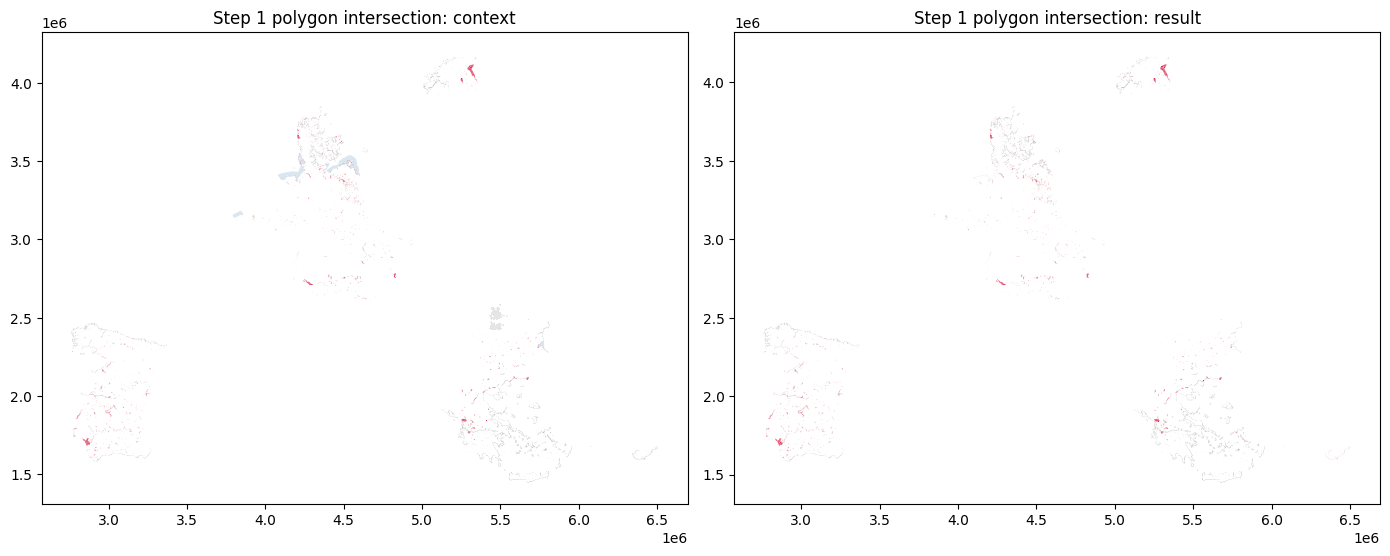

In [12]:
show_operation_maps(
    [(polygon_source_context, "steelblue"), (polygon_catchment_context, "grey")],
    sWB_p_CCM_catch_raw,
    "Step 1 polygon intersection",
)


## Step 2 - Polygon Association Identifier


In [13]:
current_stage = "Step 2 polygon association identifier"
sWB_p_CCM_catch_raw["WB_CCM_ID"] = make_association_id(sWB_p_CCM_catch_raw)
sWB_p_CCM_catch_raw = sWB_p_CCM_catch_raw[[
    "WB_code", "Full_area", "WSO1_ID", "PC_area", "WB_CCM_ID", "geometry",
]]
report["invariants"]["polygon_association_id_nonnull"] = bool(
    sWB_p_CCM_catch_raw["WB_CCM_ID"].notna().all()
)


## Step 3 - Dissolve Polygon Associations


In [14]:
validate_group_consistency(
    sWB_p_CCM_catch_raw,
    "WB_CCM_ID",
    ["WB_code", "Full_area", "WSO1_ID", "PC_area"],
)
sWB_p_CCM_catch = sWB_p_CCM_catch_raw.dissolve(
    by="WB_CCM_ID",
    aggfunc={
        "WB_code": "first", "Full_area": "first",
        "WSO1_ID": "first", "PC_area": "first",
    },
    as_index=False,
)
if sWB_p_CCM_catch["WB_CCM_ID"].duplicated().any():
    raise RuntimeError("Step 3 did not produce one polygon row per association")
report["counts"]["polygon_dissolved"] = len(sWB_p_CCM_catch)

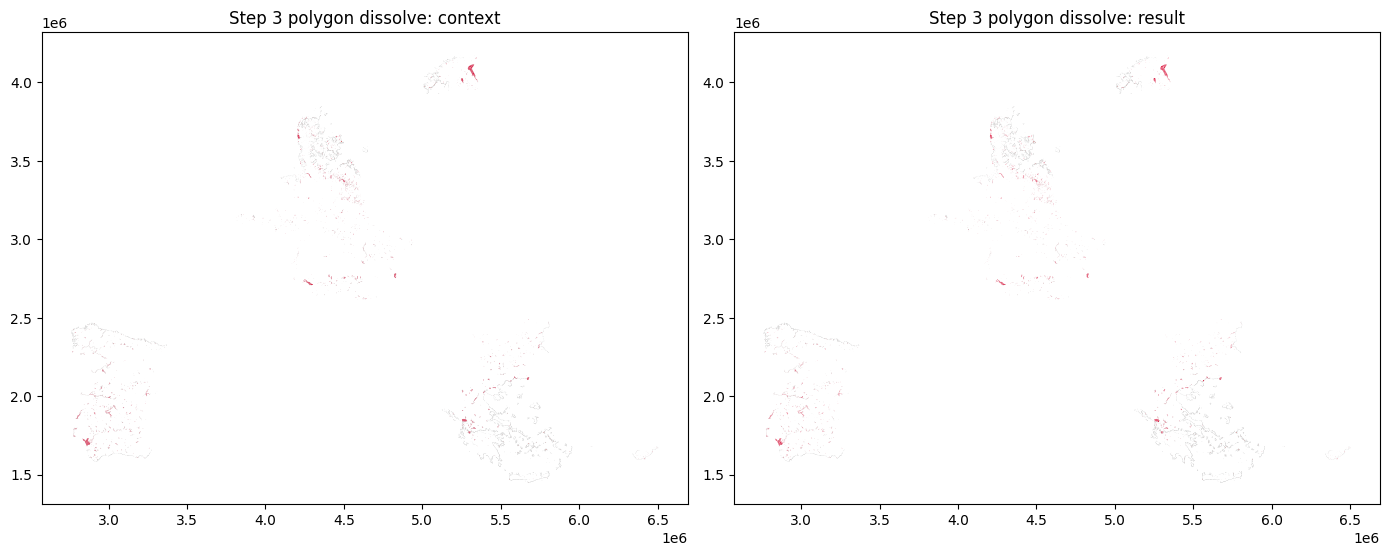

In [15]:
show_operation_maps(
    [(sWB_p_CCM_catch_raw, "grey")], sWB_p_CCM_catch,
    "Step 3 polygon dissolve",
)


## Step 4 - Dissolved Polygon Area


In [16]:
current_stage = "Step 4 dissolved polygon area"
coerce_numeric_field(
    sWB_p_CCM_catch, "Full_area", "polygon",
    "set to null in working/output data; proportional condition unavailable; absolute condition retained",
)
coerce_numeric_field(
    sWB_p_CCM_catch, "PC_area", "polygon",
    "set to null in working/output data; association retained",
)
report["counts"]["retained_Full_area_invalid"] = int(
    (sWB_p_CCM_catch["Full_area"].isna() | (sWB_p_CCM_catch["Full_area"] <= 0)).sum()
)
report["counts"]["retained_PC_area_invalid"] = int(
    (sWB_p_CCM_catch["PC_area"].isna() | (sWB_p_CCM_catch["PC_area"] <= 0)).sum()
)
sWB_p_CCM_catch["WB_CCM2_area"] = sWB_p_CCM_catch.geometry.area
if sWB_p_CCM_catch["WB_CCM2_area"].isna().any() or (sWB_p_CCM_catch["WB_CCM2_area"] < 0).any():
    raise RuntimeError("Invalid dissolved polygon area")
sWB_p_CCM_catch = sWB_p_CCM_catch[[
    "WB_code", "Full_area", "WSO1_ID", "PC_area",
    "WB_CCM_ID", "WB_CCM2_area", "geometry",
]]


## Step 5 - Polygon Qualification Table


In [17]:
current_stage = "Step 5 polygon qualification"
polygon_masks = polygon_qualification_masks(
    sWB_p_CCM_catch["Full_area"], sWB_p_CCM_catch["WB_CCM2_area"]
)
polygon_denominator_ok = polygon_masks["denominator_ok"]
polygon_ratio = polygon_masks["ratio"]
polygon_ratio_condition = polygon_masks["ratio_condition"]
polygon_absolute_condition = polygon_masks["absolute_condition"]
polygon_qualifies = polygon_masks["qualifies"]
register_denominator_exclusions(
    sWB_p_CCM_catch, polygon_denominator_ok, "polygon", "Full_area",
    action=lambda row: (
        "qualified by independent WB_CCM2_area > 10000 condition"
        if polygon_absolute_condition.loc[row.name]
        else "excluded; proportional condition unavailable and absolute condition not met"
    ),
)
report["counts"]["polygon_invalid_Full_area"] = int((~polygon_denominator_ok).sum())
report["ratio_diagnostics"].update({
    "polygon_valid_ratio_count": int(polygon_ratio.notna().sum()),
    "polygon_ratio_min": None if polygon_ratio.dropna().empty else float(polygon_ratio.min()),
    "polygon_ratio_max": None if polygon_ratio.dropna().empty else float(polygon_ratio.max()),
    "polygon_ratio_above_1": int((polygon_ratio > 1).sum()),
    "polygon_ratio_above_1_action": "retained; accepted cross-resolution condition",
})
polygon_ratio_only = polygon_ratio_condition & ~polygon_absolute_condition
polygon_absolute_only = polygon_absolute_condition & ~polygon_ratio_condition
polygon_both = polygon_ratio_condition & polygon_absolute_condition
polygon_neither = ~polygon_ratio_condition & ~polygon_absolute_condition
report["counts"].update({
    "polygon_qualified_ratio_only": int(polygon_ratio_only.sum()),
    "polygon_qualified_absolute_only": int(polygon_absolute_only.sum()),
    "polygon_qualified_both": int(polygon_both.sum()),
    "polygon_qualified_neither": int(polygon_neither.sum()),
})
sWB_p_CCM_tbl = pd.DataFrame(
    sWB_p_CCM_catch.loc[polygon_qualifies, [
        "WB_code", "Full_area", "WSO1_ID", "PC_area",
        "WB_CCM2_area", "WB_CCM_ID",
    ]]
)
report["counts"]["polygon_qualified"] = len(sWB_p_CCM_tbl)


## Step 6 - Line Intersection


In [18]:
current_stage = "Step 6 line intersection"
sWB_l_CCM_catch_raw, line_source_context, line_catchment_context = run_intersection_batches(
    "SurfaceWaterBodyLine", "line", "line", "Full_length", "Segment_length"
)
if sWB_l_CCM_catch_raw.empty:
    raise RuntimeError("Step 6 produced no line intersections")
sWB_l_CCM_catch_raw.shape


(549600, 5)

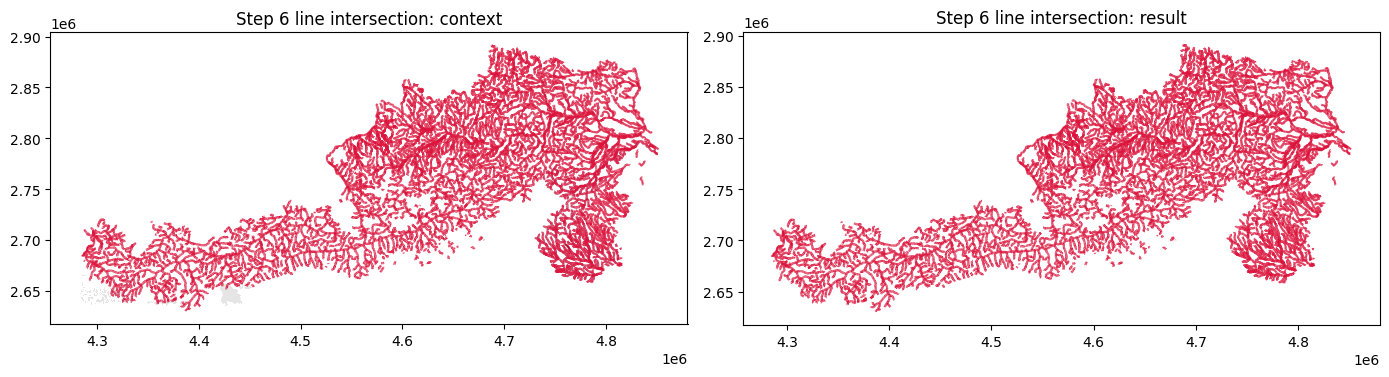

In [19]:
show_operation_maps(
    [(line_source_context, "steelblue"), (line_catchment_context, "grey")],
    sWB_l_CCM_catch_raw,
    "Step 6 line intersection",
)


## Step 7 - Line Association Identifier


In [20]:
current_stage = "Step 7 line association identifier"
sWB_l_CCM_catch_raw["WB_CCM_ID"] = make_association_id(sWB_l_CCM_catch_raw)
sWB_l_CCM_catch_raw = sWB_l_CCM_catch_raw[[
    "WB_code", "Full_length", "WSO1_ID", "Segment_length", "WB_CCM_ID", "geometry",
]]
report["invariants"]["line_association_id_nonnull"] = bool(
    sWB_l_CCM_catch_raw["WB_CCM_ID"].notna().all()
)


## Step 8 - Dissolve Line Associations


In [21]:
validate_group_consistency(
    sWB_l_CCM_catch_raw,
    "WB_CCM_ID",
    ["WB_code", "Full_length", "WSO1_ID", "Segment_length"],
)
sWB_l_CCM_catch = sWB_l_CCM_catch_raw.dissolve(
    by="WB_CCM_ID",
    aggfunc={
        "WB_code": "first", "Full_length": "first",
        "WSO1_ID": "first", "Segment_length": "first",
    },
    as_index=False,
)
if sWB_l_CCM_catch["WB_CCM_ID"].duplicated().any():
    raise RuntimeError("Step 8 did not produce one line row per association")
report["counts"]["line_dissolved"] = len(sWB_l_CCM_catch)

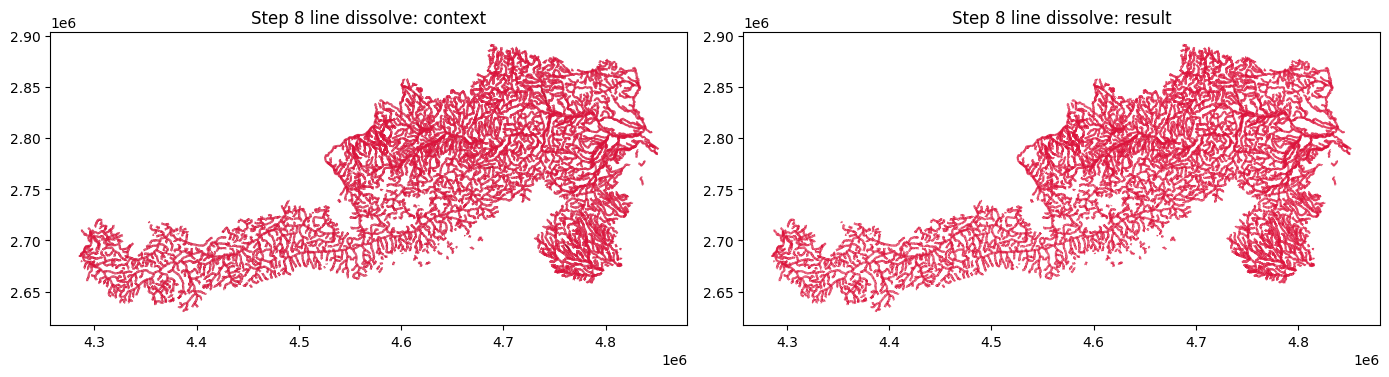

In [22]:
show_operation_maps(
    [(sWB_l_CCM_catch_raw, "grey")], sWB_l_CCM_catch,
    "Step 8 line dissolve",
)


## Step 9 - Dissolved Line Length


In [23]:
current_stage = "Step 9 dissolved line length"
coerce_numeric_field(
    sWB_l_CCM_catch, "Full_length", "line",
    "set to null in working/output data; association retained",
)
coerce_numeric_field(
    sWB_l_CCM_catch, "Segment_length", "line",
    "set to null in working/output data; excluded from line qualification",
)
report["counts"]["retained_Full_length_invalid"] = int(
    (sWB_l_CCM_catch["Full_length"].isna() | (sWB_l_CCM_catch["Full_length"] <= 0)).sum()
)
sWB_l_CCM_catch["WB_CCM2_length"] = sWB_l_CCM_catch.geometry.length
if sWB_l_CCM_catch["WB_CCM2_length"].isna().any() or (sWB_l_CCM_catch["WB_CCM2_length"] < 0).any():
    raise RuntimeError("Invalid dissolved line length")
sWB_l_CCM_catch = sWB_l_CCM_catch[[
    "WB_code", "Full_length", "WSO1_ID", "Segment_length",
    "WB_CCM_ID", "WB_CCM2_length", "geometry",
]]


## Step 10 - Line Qualification Table


In [24]:
current_stage = "Step 10 line qualification"
line_masks = line_qualification_masks(
    sWB_l_CCM_catch["Segment_length"], sWB_l_CCM_catch["WB_CCM2_length"]
)
line_denominator_ok = line_masks["denominator_ok"]
line_ratio = line_masks["ratio"]
line_qualifies = line_masks["qualifies"]
register_denominator_exclusions(sWB_l_CCM_catch, line_denominator_ok, "line", "Segment_length")
report["counts"]["line_invalid_Segment_length"] = int((~line_denominator_ok).sum())
report["ratio_diagnostics"].update({
    "line_valid_ratio_count": int(line_ratio.notna().sum()),
    "line_ratio_min": None if line_ratio.dropna().empty else float(line_ratio.min()),
    "line_ratio_max": None if line_ratio.dropna().empty else float(line_ratio.max()),
    "line_ratio_above_1": int((line_ratio > 1).sum()),
    "line_ratio_above_1_action": "retained; accepted cross-resolution condition",
})
sWB_l_CCM_tbl = pd.DataFrame(
    sWB_l_CCM_catch.loc[line_qualifies, [
        "WB_code", "Full_length", "WSO1_ID", "Segment_length",
        "WB_CCM2_length", "WB_CCM_ID",
    ]]
)
report["counts"]["line_qualified"] = len(sWB_l_CCM_tbl)


## Step 11 - Append Tables


In [25]:
combined_columns = [
    "WB_CCM_ID", "WB_code", "WSO1_ID",
    "Full_area", "PC_area", "WB_CCM2_area",
    "Full_length", "Segment_length", "WB_CCM2_length",
]
sWB_CCM_tbl = pd.concat(
    [
        sWB_p_CCM_tbl.reindex(columns=combined_columns),
        sWB_l_CCM_tbl.reindex(columns=combined_columns),
    ],
    ignore_index=True,
)
expected_append_count = len(sWB_p_CCM_tbl) + len(sWB_l_CCM_tbl)
if len(sWB_CCM_tbl) != expected_append_count:
    raise RuntimeError("Append row-count invariant failed")
report["counts"]["appended"] = len(sWB_CCM_tbl)

## Step 12 - Network-Left Join


In [26]:
for frame in (sWB_CCM_tbl, network_data):
    frame["WSO1_ID"] = pd.to_numeric(frame["WSO1_ID"], errors="raise").astype("Int64")
missing_network_ids = sorted(set(sWB_CCM_tbl["WSO1_ID"].dropna().astype(int)) - network_ids)
if missing_network_ids:
    raise RuntimeError(f"Association WSO1_ID values missing from Network_data: {missing_network_ids[:20]}")
association_count = len(sWB_CCM_tbl)
sWB_CCM_tbl = network_data.merge(
    sWB_CCM_tbl, how="left", on="WSO1_ID", validate="one_to_many"
)
sWB_CCM_tbl = sWB_CCM_tbl[[
    "WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID",
    "Full_area", "PC_area", "WB_CCM2_area", "Full_length",
    "Segment_length", "WB_CCM2_length", "Source_ID", "dist_mouth",
]]
report["counts"]["network_only_rows"] = int(sWB_CCM_tbl["WB_code"].isna().sum())


## Step 13 - Minimum-Distance Mouth Candidates


In [27]:
valid = sWB_CCM_tbl["WB_code"].notna() & sWB_CCM_tbl["dist_mouth"].notna()
candidate = sWB_CCM_tbl.loc[valid].copy()
mins = candidate.groupby("WB_code")["dist_mouth"].transform("min")
sWB_CCM_mouth_raw_tbl = candidate.loc[candidate["dist_mouth"].eq(mins)].copy()
report["counts"]["mouth_raw_rows"] = len(sWB_CCM_mouth_raw_tbl)


## Steps 14-16 - Association Counts


In [28]:
Num_WSO1_ID_per_WBcode_tbl = (
    sWB_CCM_tbl.loc[sWB_CCM_tbl["WB_code"].notna()]
    .groupby("WB_code", as_index=False)["WSO1_ID"].nunique()
    .rename(columns={"WSO1_ID": "Num_WSO1_ID"})
)
Num_WBcode_per_WSO1_ID_tbl = (
    sWB_CCM_tbl.groupby("WSO1_ID", as_index=False, dropna=False)["WB_code"].nunique()
    .rename(columns={"WB_code": "Num_WB_code"})
)
Num_WBcode_per_WSO1_ID_tbl["Num_WB_code_downstream"] = Num_WBcode_per_WSO1_ID_tbl["Num_WB_code"]


## Steps 17-20 - Simple Table and Selective Joins


In [29]:
sWB_CCM_simple_tbl = sWB_CCM_tbl.loc[sWB_CCM_tbl["WB_CCM_ID"].notna(), [
    "WB_CCM_ID", "WB_code", "WSO1_ID", "nextdownWSO1_ID", "Source_ID"
]].copy()
sWB_CCM_j1_tbl = sWB_CCM_simple_tbl.merge(
    Num_WSO1_ID_per_WBcode_tbl, how="left", on="WB_code", validate="many_to_one"
)
sWB_CCM_j2_tbl = sWB_CCM_j1_tbl.merge(
    Num_WBcode_per_WSO1_ID_tbl[["WSO1_ID", "Num_WB_code"]],
    how="left", on="WSO1_ID", validate="many_to_one",
)
sWB_CCM_small_WB_search_tbl = sWB_CCM_j2_tbl.merge(
    Num_WBcode_per_WSO1_ID_tbl[["WSO1_ID", "Num_WB_code_downstream"]],
    how="left", left_on="nextdownWSO1_ID", right_on="WSO1_ID",
    suffixes=("", "_downstream_key"), validate="many_to_one",
).drop(columns=["WSO1_ID_downstream_key"])


## Step 21 - Upstream Water-Body-Code Status


In [30]:
upstream_groups = {
    key: group["Num_WB_code"]
    for key, group in sWB_CCM_small_WB_search_tbl.groupby("nextdownWSO1_ID", dropna=False)
}
def upstream_status(wso1_id):
    values = upstream_groups.get(wso1_id)
    if values is None or len(values) < 2 or values.isna().any():
        return pd.NA
    return 1 if values.gt(0).all() else 0
sWB_CCM_small_WB_search_tbl["WB_code_upstream"] = pd.array(
    [upstream_status(v) for v in sWB_CCM_small_WB_search_tbl["WSO1_ID"]], dtype="Int64"
)


## Step 22 - Small-Water-Body Exclusion Table


In [31]:
u = sWB_CCM_small_WB_search_tbl["WB_code_upstream"]
small_mask = (
    sWB_CCM_small_WB_search_tbl["Num_WSO1_ID"].eq(1)
    & sWB_CCM_small_WB_search_tbl["Num_WB_code"].gt(1)
    & (
        sWB_CCM_small_WB_search_tbl["Num_WB_code_downstream"].gt(0)
        | sWB_CCM_small_WB_search_tbl["nextdownWSO1_ID"].eq(-9999)
    )
    & (u.isna() | u.ne(1) | sWB_CCM_small_WB_search_tbl["Source_ID"].eq(
        sWB_CCM_small_WB_search_tbl["WSO1_ID"]
    ))
)
sWB_CCM_small_WB_tbl = sWB_CCM_small_WB_search_tbl.loc[small_mask.fillna(False)].copy()


## Step 23 - Final Left Anti-Join


In [32]:
excluded_ids = set(sWB_CCM_small_WB_tbl["WB_CCM_ID"].dropna())
sWB_CCM_mouth_tbl = sWB_CCM_mouth_raw_tbl.loc[
    ~sWB_CCM_mouth_raw_tbl["WB_CCM_ID"].isin(excluded_ids)
].copy()
report["counts"].update({
    "small_WB_exclusion_rows": len(sWB_CCM_small_WB_tbl),
    "final_rows": len(sWB_CCM_mouth_tbl),
    "tied_mouth_rows": int(sWB_CCM_mouth_raw_tbl.duplicated("WB_code", keep=False).sum()),
})


In [33]:
current_stage = "write staging GeoPackage"

expected_frames = {
    "sWB_p_CCM_catch_raw": sWB_p_CCM_catch_raw,
    "sWB_p_CCM_catch": sWB_p_CCM_catch,
    "sWB_p_CCM_tbl": sWB_p_CCM_tbl,
    "sWB_l_CCM_catch_raw": sWB_l_CCM_catch_raw,
    "sWB_l_CCM_catch": sWB_l_CCM_catch,
    "sWB_l_CCM_tbl": sWB_l_CCM_tbl,
    "sWB_CCM_tbl": sWB_CCM_tbl,
    "sWB_CCM_mouth_raw_tbl": sWB_CCM_mouth_raw_tbl,
    "Num_WSO1_ID_per_WBcode_tbl": Num_WSO1_ID_per_WBcode_tbl,
    "Num_WBcode_per_WSO1_ID_tbl": Num_WBcode_per_WSO1_ID_tbl,
    "sWB_CCM_simple_tbl": sWB_CCM_simple_tbl,
    "sWB_CCM_j1_tbl": sWB_CCM_j1_tbl,
    "sWB_CCM_j2_tbl": sWB_CCM_j2_tbl,
    "sWB_CCM_small_WB_search_tbl": sWB_CCM_small_WB_search_tbl,
    "sWB_CCM_small_WB_tbl": sWB_CCM_small_WB_tbl,
    "sWB_CCM_mouth_tbl": sWB_CCM_mouth_tbl,
}


def write_layer(frame, layer):
    pyogrio.write_dataframe(frame, output_gpkg, layer=layer, driver="GPKG")
    available = {str(row[0]) for row in pyogrio.list_layers(output_gpkg)}
    if layer not in available:
        raise RuntimeError(f"Output layer is not discoverable after write: {layer}")
    report["outputs"].append(layer)


for layer_name in OUTPUT_SCHEMAS:
    write_layer(expected_frames[layer_name], layer_name)

for dataset, records in quarantine_frames.items():
    if records:
        frame = gpd.GeoDataFrame(records, geometry="geometry", crs="EPSG:3035")
        pyogrio.write_dataframe(
            frame, quarantine_path, layer=f"{dataset}_quarantine", driver="GPKG"
        )

if repair_overview_records:
    overview_path = repair_map_dir / "geometry_repair_overview.png"
    overview = gpd.GeoDataFrame(repair_overview_records, geometry="geometry", crs="EPSG:3035")
    ax = overview.plot(figsize=(12, 10), column="dataset", legend=True, alpha=0.7)
    ax.set_title("Geometry repairs and affected records")
    ax.set_aspect("equal")
    ax.figure.tight_layout()
    ax.figure.savefig(overview_path, dpi=150)
    plt.close(ax.figure)


In [34]:
current_stage = "final output schema and equivalence validation"

def output_epsg(info):
    crs_value = info.get("crs")
    if not crs_value:
        return None
    return gpd.GeoSeries([], crs=crs_value).crs.to_epsg()


def validate_output_schema(layer, frame, specification):
    info = pyogrio.read_info(output_gpkg, layer=layer)
    actual_fields = list(map(str, info.get("fields", [])))
    fields_match = actual_fields == specification["fields"]
    count_match = int(info.get("features", -1)) == len(frame)
    geometry_type = str(info.get("geometry_type"))
    spatial_match = (geometry_type not in {"None", "Unknown", ""}) == specification["spatial"]
    geometry_match = True
    crs_match = True
    if specification["spatial"]:
        family = specification["family"]
        geometry_match = (
            "Polygon" in geometry_type if family == "polygon" else "LineString" in geometry_type
        )
        crs_match = output_epsg(info) == specification["epsg"]
    check = {
        "layer": layer,
        "passed": all([fields_match, count_match, spatial_match, geometry_match, crs_match]),
        "fields_match": fields_match,
        "count_match": count_match,
        "spatial_match": spatial_match,
        "geometry_match": geometry_match,
        "crs_match": crs_match,
        "expected_fields": specification["fields"],
        "actual_fields": actual_fields,
        "expected_count": len(frame),
        "actual_count": int(info.get("features", -1)),
        "geometry_type": geometry_type,
        "epsg": output_epsg(info),
    }
    report["output_schema_checks"][layer] = check
    if not check["passed"]:
        raise RuntimeError(f"Output schema validation failed for {layer}: {check}")


def normalized_output(path, layer, specification):
    frame = pyogrio.read_dataframe(path, layer=layer)
    attributes = frame[specification["fields"]].copy()
    normalized = attributes.astype("string").fillna("<NA>")
    if specification["spatial"]:
        geometries = shapely.normalize(force_2d(frame.geometry.array))
        normalized["_geometry_wkb"] = pd.Series(shapely.to_wkb(geometries, hex=True), dtype="string")
    sort_columns = list(normalized.columns)
    return normalized.sort_values(sort_columns, kind="mergesort").reset_index(drop=True)


def compare_output_geopackages(reference_path, candidate_path):
    comparison = {
        "requested": True,
        "reference_input_format": "gpkg" if input_format == "gdb" else "gdb",
        "candidate_input_format": input_format,
        "reference": str(reference_path),
        "candidate": str(candidate_path),
        "candidate_published_as": str(final_output_gpkg),
    }
    if not reference_path.is_file():
        raise RuntimeError(f"Cross-format reference output does not exist: {reference_path}")
    reference_layers = {str(row[0]) for row in pyogrio.list_layers(reference_path)}
    candidate_layers = {str(row[0]) for row in pyogrio.list_layers(candidate_path)}
    comparison["layer_sets_match"] = reference_layers == candidate_layers == set(OUTPUT_SCHEMAS)
    if not comparison["layer_sets_match"]:
        raise RuntimeError(f"Cross-format layer mismatch: {reference_layers} vs {candidate_layers}")
    for layer, specification in OUTPUT_SCHEMAS.items():
        reference_info = pyogrio.read_info(reference_path, layer=layer)
        candidate_info = pyogrio.read_info(candidate_path, layer=layer)
        schema_match = list(map(str, reference_info.get("fields", []))) == list(map(str, candidate_info.get("fields", [])))
        count_match = int(reference_info.get("features", -1)) == int(candidate_info.get("features", -1))
        content_match = normalized_output(reference_path, layer, specification).equals(
            normalized_output(candidate_path, layer, specification)
        )
        comparison[f"{layer}_schema"] = schema_match
        comparison[f"{layer}_count"] = count_match
        comparison[f"{layer}_content"] = content_match
        if not all([schema_match, count_match, content_match]):
            raise RuntimeError(f"Cross-format equivalence failed for {layer}")
    comparison["all_outputs_equivalent"] = True
    return comparison


expected_outputs = set(OUTPUT_SCHEMAS)
actual_outputs = {str(row[0]) for row in pyogrio.list_layers(output_gpkg)}
missing_outputs = sorted(expected_outputs - actual_outputs)
if missing_outputs:
    raise RuntimeError(f"Missing required outputs: {missing_outputs}")
for layer_name, specification in OUTPUT_SCHEMAS.items():
    validate_output_schema(layer_name, expected_frames[layer_name], specification)

if compare_with_existing_output:
    report["cross_format_equivalence"] = compare_output_geopackages(
        final_output_gpkg, output_gpkg
    )
else:
    report["cross_format_equivalence"] = {
        "requested": False,
        "status": "not requested for this run",
    }

failed_batches = [batch for batch in report["batches"] if batch["status"] != "complete"]
if failed_batches:
    raise RuntimeError(f"Failed batches remain: {failed_batches}")
completion_status = "complete with exclusions" if report["quarantine"] else "complete"
report["invariants"].update({
    "strict_polygon_thresholds": True,
    "strict_line_threshold": True,
    "polygon_rule": "WB_CCM2_area / Full_area > 0.1 OR WB_CCM2_area > 10000 m2",
    "polygon_denominator": "Full_area",
    "polygon_absolute_threshold_m2": 10000,
    "line_denominator": "Segment_length",
    "polygon_qualification_partition": int(
        polygon_ratio_only.sum() + polygon_absolute_only.sum()
        + polygon_both.sum() + polygon_neither.sum()
    ) == len(sWB_p_CCM_catch),
    "all_batches_complete": not failed_batches,
    "append_count": association_count == expected_append_count,
    "network_left_join_preserved": len(sWB_CCM_tbl) >= len(network_data),
    "network_id_unique": not network_data["WSO1_ID"].duplicated().any(),
    "network_only_rows_preserved": True,
    "null_distance_excluded_only_from_minimum_selection": True,
    "all_expected_outputs_present": actual_outputs == expected_outputs,
    "all_output_schemas_valid": all(item["passed"] for item in report["output_schema_checks"].values()),
})
failed_invariants = [key for key, value in report["invariants"].items() if isinstance(value, bool) and not value]
if failed_invariants:
    raise RuntimeError(f"Final workflow invariants failed: {failed_invariants}")

qc = pd.Series({
    "status": completion_status,
    "input_format": input_format,
    "run_profile": run_profile,
    "batches": len(report["batches"]),
    "failed_batches": len(failed_batches),
    "unique_candidate_catchments": len(catchment_registry),
    "geometry_quarantine_records": len(report["quarantine"]),
    "network_only_rows": report["counts"].get("network_only_rows", 0),
    "small_WB_exclusion_rows": len(sWB_CCM_small_WB_tbl),
    "final_rows": len(sWB_CCM_mouth_tbl),
    "staging_output_gpkg": str(output_gpkg),
    "final_output_gpkg": str(final_output_gpkg),
    "validation_report": str(validation_report_path),
})
qc


status                                                                  complete
input_format                                                                gpkg
run_profile                                                                 full
batches                                                                      358
failed_batches                                                                 0
unique_candidate_catchments                                              1023297
geometry_quarantine_records                                                    0
network_only_rows                                                        1000167
small_WB_exclusion_rows                                                    27451
final_rows                                                                100045
staging_output_gpkg            /Users/eleshuk/Documents/ISA_class_materials/T...
final_output_gpkg              /Users/eleshuk/Documents/ISA_class_materials/T...
validation_report           

In [35]:
current_stage = "publish validated outputs"

if repair_map_dir.exists() and not populated_directory(repair_map_dir):
    remove_generated_tree_with_retries(repair_map_dir, cache_dir)

publication_entries = [
    ("workflow_output", output_gpkg, final_output_gpkg),
    ("geometry_quarantine", quarantine_path, final_quarantine_path),
    ("geometry_repair_maps", repair_map_dir, final_repair_map_dir),
]
publication_manifest = promote_deliverable_set(publication_entries)
report["publication"]["status"] = "promoted and validated"

bridge_cleanup_status = "not used"
if report["gdb_bridge"]["used"]:
    try:
        remove_generated_tree_with_retries(bridge_dir, bridge_root)
        bridge_cleanup_status = "deleted after successful completion"
        if bridge_root.exists() and not any(bridge_root.iterdir()):
            remove_generated_tree_with_retries(bridge_root, run_output_dir)
    except (PermissionError, OSError) as exc:
        bridge_cleanup_status = f"retained because Windows denied cleanup after retries: {exc}"
        report["warnings"].append(bridge_cleanup_status)
report["gdb_bridge"]["cleanup"] = bridge_cleanup_status

report["published_output"] = str(final_output_gpkg)
report["outputs"] = [item for item in report["outputs"] if item in OUTPUT_SCHEMAS]
report["outputs"].append(str(final_output_gpkg))
if final_quarantine_path.is_file():
    report["outputs"].append(str(final_quarantine_path))
if populated_directory(final_repair_map_dir):
    report["outputs"].append(str(final_repair_map_dir))

write_validation_report(completion_status)
publication_manifest["state"] = "committed"
save_publication_manifest(publication_manifest)
if publication_backup_dir.exists():
    remove_generated_tree_with_retries(publication_backup_dir, run_output_dir)
publication_manifest_path.unlink()
report["publication"]["status"] = "committed"

cache_cleanup_status = "retained by configuration"
if not retain_cache_after_success:
    if cache_dir.exists():
        try:
            remove_generated_tree_with_retries(cache_dir, run_output_dir)
            cache_cleanup_status = "deleted after successful completion"
        except (PermissionError, OSError) as exc:
            cache_cleanup_status = f"retained because Windows denied cleanup: {exc}"
            report["warnings"].append(cache_cleanup_status)
report["cache_cleanup"] = cache_cleanup_status
write_validation_report(completion_status)
_wfd_report_finalized = True
if _ipython is not None:
    _ipython.events.unregister("post_run_cell", _capture_notebook_failure)

print(f"Validation report: {validation_report_path}")
print(f"Workflow output: {final_output_gpkg}")
print(f"Completion status: {completion_status}")


Validation report: /Users/eleshuk/Documents/ISA_class_materials/Thesis/Spatial_workflow_work/Workflow_WFD/Output/data_validation_report.md
Workflow output: /Users/eleshuk/Documents/ISA_class_materials/Thesis/Spatial_workflow_work/Workflow_WFD/Output/Workflow_outputs.gpkg
Completion status: complete


## Final Workflow Summary

The selected input is validated without modification. Working geometries are cleaned, made 2D, repaired or quarantined as required, and processed in EPSG:3035. Polygon and line intersections are dissolved globally before strict qualification.

The qualifying associations are appended, enriched with the complete `Network_data` table, summarized by water body and network segment, evaluated for upstream/downstream small-water-body conditions, and removed from the tied minimum-distance candidates by a left anti-join. Sixteen outputs are staged and validated before publication.

Known no-watercourse rows are accepted only when the complete optional network triplet is null and its identifiers exactly match catchments with null `Segment_length`. Consult the final quality-control cell and `data_validation_report.md` for the actual completion status.
